# Machine Learning — Polynomial Regression on the Nipah Outbreak Series
## Model development, validation and honest reporting

---

This notebook is the **machine-learning counterpart** to
`nipah_time_series_analysis.ipynb`. Where that notebook answers epidemiological
business questions, this one does one thing thoroughly: **build, validate and
ship a polynomial-regression model** for the annual Nipah case series — and
establish exactly how much that model can be trusted.

### The task

| | |
|---|---|
| **Problem type** | Supervised regression on a univariate time index |
| **Feature** | `years_since_1998` (a single numeric feature) |
| **Primary target** | `cases_total` — confirmed Nipah cases per year, India + Bangladesh |
| **Training data** | **n = 29** (1998–2026) |
| **Model family** | Polynomial regression (degree × ridge penalty × variance-stabilising transform) |
| **Validation** | Leave-one-out cross-validation, scored on the original scale |
| **Deliverable** | Seven serialised models in `models/` + a model card |

### The one rule this notebook follows

> **A model is only useful if it beats the simplest thing that could possibly work.**

Every model here is scored against a **"predict the historical mean" baseline**
put through the *same* cross-validation split. That single discipline turns out
to decide the entire result — and it is why this notebook reports failures
alongside successes rather than only the models that worked.

### What you will find

1. Dataset card and why this is a hard learning problem
2. Baselines **first**, before any model
3. Feature engineering: the polynomial expansion and why scaling order matters
4. Target transformations
5. Cross-validation strategy — does the choice change the answer?
6. The regularisation path — and what the selected penalty reveals
7. Bias–variance decomposition and the learning curve
8. The full model-selection grid search
9. Benchmark against rival learners (trees, boosting, KNN, SVR, count GLMs)
10. Is the difference even real? A bootstrap confidence interval on the gap
11. Feature-engineering attempts
12. A two-part hurdle model — including a spectacular failure
13. Residual diagnostics
14. Prediction intervals and backtested coverage
15. Regime-aware training
16. Final training, persistence, inference demo and model card

---
## 1. Setup

In [1]:
from __future__ import annotations

import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.stattools import durbin_watson

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import (ElasticNet, LinearRegression, Lasso,
                                  LogisticRegression, Ridge)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, LeaveOneOut, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "input").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root (no 'input' folder found).")


ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))

import nipah_data as nd            # noqa: E402
import train_models as tm          # noqa: E402

IMG_DIR, OUTPUT_DIR, MODELS_DIR = ROOT / "img", ROOT / "output", ROOT / "models"
for folder in (IMG_DIR, OUTPUT_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

C = {
    "case": "#457B9D", "death": "#B23A48", "good": "#2A9D8F", "warn": "#E9C46A",
    "accent": "#3D5A80", "dark": "#22333B", "muted": "#8D99AE", "grid": "#E4E7EB",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "axes.labelcolor": C["dark"],
    "axes.edgecolor": C["muted"], "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
sns.set_style("white", {"axes.grid": True, "grid.color": C["grid"]})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 0


def style_axes(ax, ylabel=None, xlabel=None, title=None):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.9)
    ax.grid(axis="x", visible=False)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    if title: ax.set_title(title, loc="left", pad=11)
    return ax


def save_fig(fig, name):
    fig.savefig(IMG_DIR / f"{name}.png", facecolor="white")


print(f"Project root : {ROOT}")
print(f"scikit-learn pipeline helpers imported from src/train_models.py")
print("Setup complete.")

Project root : C:\Users\rafae.RAFAEL_NOTEBOOK\OneDrive\Documentos\Projetos_data_science_IA\kaggle\Projetos_kaggle\Nipah Virus Outbreaks 2025-2026 India & Bangladesh
scikit-learn pipeline helpers imported from src/train_models.py
Setup complete.


### Analysis

The notebook reuses `src/nipah_data.py` for data access and `src/train_models.py`
for the model pipeline, so nothing is reimplemented here. `tm.make_pipeline(degree,
alpha)` and `tm.TRANSFORMS` are the exact objects that produce the artefacts in
`models/` — what is validated below is what ships, not a notebook-only copy of it.

`RANDOM_STATE = 0` is fixed throughout. Every bootstrap, subsample and stochastic
learner in this notebook is seeded, so the numbers in the commentary reproduce
exactly on re-execution.

---
## 2. Dataset card — and why this is a hard learning problem

In [2]:
annual = nd.build_annual_series()
outbreak_only = annual[annual["cases"] > 0]

X_all = annual["years_since_start"].to_numpy(float).reshape(-1, 1)
y_all = annual["cases"].to_numpy(float)
X_ob = (outbreak_only["year"].to_numpy() - nd.FIRST_YEAR).astype(float).reshape(-1, 1)
y_ob = outbreak_only["cases"].to_numpy(float)
YEARS = annual["year"].to_numpy()

print("DATASET CARD")
print("=" * 74)
print(f"  Observations (n)          : {len(annual)}")
print(f"  Feature                   : years_since_1998, integer 0..{int(X_all.max())}")
print(f"  Target                    : cases_total (non-negative integer count)")
print(f"  Train/test split          : none — n is too small; LOO cross-validation instead")
print()
print("TARGET DISTRIBUTION")
print("=" * 74)
print(f"  mean {y_all.mean():.2f}   sd {y_all.std(ddof=1):.2f}   "
      f"median {np.median(y_all):.1f}   min {y_all.min():.0f}   max {y_all.max():.0f}")
print(f"  IQR  {np.percentile(y_all, 25):.1f} – {np.percentile(y_all, 75):.1f}")
print(f"  skewness {stats.skew(y_all):+.3f}   excess kurtosis {stats.kurtosis(y_all):+.3f}")
print(f"  zeros    {(y_all == 0).sum()}/{len(y_all)} ({(y_all == 0).mean() * 100:.1f}%)")
print(f"  variance / mean = {y_all.var(ddof=1) / y_all.mean():.2f}   "
      f"(Poisson would be 1.00)")
print()
print("SECONDARY TARGET — outbreak years only (cases > 0)")
print("=" * 74)
print(f"  n {len(y_ob)}   mean {y_ob.mean():.2f}   sd {y_ob.std(ddof=1):.2f}   "
      f"skew {stats.skew(y_ob):+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.bar(YEARS, y_all, color=C["case"], width=0.7, zorder=3)
ax.axhline(y_all.mean(), color=C["death"], ls="--", lw=1.8,
           label=f"mean = {y_all.mean():.1f}")
style_axes(ax, "Cases", "Year", "The series to be learned")
ax.legend()

ax = axes[1]
ax.hist(y_all, bins=np.arange(0, 90, 6), color=C["case"], edgecolor="white", zorder=3)
style_axes(ax, "Frequency", "Cases in a year",
           f"Right-skewed, zero-inflated (skew {stats.skew(y_all):+.2f})")

ax = axes[2]
ax.scatter(X_all.ravel(), y_all, s=62, color=C["case"],
           edgecolor=C["dark"], linewidth=0.7, zorder=4)
ax.axhline(y_all.mean(), color=C["death"], ls="--", lw=1.6, label="mean")
style_axes(ax, "cases (target)", "years_since_1998 (feature)",
           "The entire feature space — one dimension")
ax.legend()
fig.tight_layout()
save_fig(fig, "ml01_dataset")
plt.show()

DATASET CARD
  Observations (n)          : 29
  Feature                   : years_since_1998, integer 0..28
  Target                    : cases_total (non-negative integer count)
  Train/test split          : none — n is too small; LOO cross-validation instead

TARGET DISTRIBUTION
  mean 14.24   sd 19.27   median 9.0   min 0   max 79
  IQR  0.0 – 18.0
  skewness +2.030   excess kurtosis +3.822
  zeros    9/29 (31.0%)
  variance / mean = 26.06   (Poisson would be 1.00)

SECONDARY TARGET — outbreak years only (cases > 0)
  n 20   mean 20.65   sd 20.19   skew +1.779


<Figure size 1650x440 with 3 Axes>

### Analysis

**Three properties make this a genuinely hard learning problem, and all three are
visible in the third panel.**

| Property | Value | Why it hurts |
|---|---|---|
| **Tiny sample** | n = 29 | No held-out test set is affordable; a degree-6 fit spends 7 of 29 degrees of freedom |
| **Zero-inflated** | 9/29 years are 0 (31.0%) | The target is a *mixture* of two processes, not one smooth function |
| **Severely overdispersed** | variance/mean = **26.06** | Any Poisson-based inference will be ~√26 ≈ 5× overconfident |
| **Right-skewed** | skew **+2.030**, kurtosis +3.82 | Least-squares and normal prediction intervals are both mis-specified |

**The scatter plot in the third panel is the honest picture of what the model has
to work with.** One feature, 29 points, and no visible functional relationship —
just a cloud of points with a dense band of zeros along the bottom and three
outliers at the top (2001: 79, 2004: 65, 2011: 43).

**There is no train/test split in this notebook, and that is deliberate.** A 20%
test set would be 6 points — an RMSE computed on 6 points has a confidence
interval so wide it could not distinguish any two models. Leave-one-out
cross-validation uses all 29 points as test points exactly once, which is the
only defensible choice at this sample size. Its known weakness (high variance in
the estimate) is addressed directly in Section 11 with a bootstrap confidence
interval.

**The secondary target matters.** Restricting to the 20 years with cases > 0
removes the zero-inflation and isolates a cleaner question: *given that an
outbreak happened, how big was it?* Section 12 tests whether separating the
mixture this way actually helps.

---
## 3. Baselines first — before any model is fitted

In [3]:
def loo_predictions(make_model, X, y, transform="identity", ceiling=None):
    """Leave-one-out predictions, always returned on the ORIGINAL scale."""
    forward, inverse = tm.TRANSFORMS[transform]
    y_t = forward(y)
    preds = np.empty(len(y))
    for train_idx, test_idx in LeaveOneOut().split(X):
        model = make_model().fit(X[train_idx], y_t[train_idx])
        value = np.clip(inverse(model.predict(X[test_idx])), 0, None)
        preds[test_idx] = np.clip(value, 0, ceiling) if ceiling else value
    return preds


def score(preds, y):
    return (float(np.sqrt(mean_squared_error(y, preds))),
            float(mean_absolute_error(y, preds)),
            float(r2_score(y, preds)))


BASELINES = {
    "predict the mean":   lambda: DummyRegressor(strategy="mean"),
    "predict the median": lambda: DummyRegressor(strategy="median"),
    "predict zero":       lambda: DummyRegressor(strategy="constant", constant=0.0),
}

print("BASELINES — leave-one-out cross-validated, cases_total")
print("=" * 74)
print(f"  {'strategy':<22}{'RMSE':>9}{'MAE':>9}{'R2':>10}")
baseline_scores = {}
for name, make in BASELINES.items():
    r, m, r2 = score(loo_predictions(make, X_all, y_all), y_all)
    baseline_scores[name] = r
    print(f"  {name:<22}{r:>9.2f}{m:>9.2f}{r2:>+10.3f}")

naive = y_all[:-1]
r_n = np.sqrt(mean_squared_error(y_all[1:], naive))
print(f"  {'naive (last year)':<22}{r_n:>9.2f}"
      f"{mean_absolute_error(y_all[1:], naive):>9.2f}"
      f"{r2_score(y_all[1:], naive):>+10.3f}   (n=28)")

BASELINE_RMSE = baseline_scores["predict the mean"]
print(f"\n  >>> THE BAR TO BEAT: RMSE = {BASELINE_RMSE:.2f} <<<")
print(f"\n  Note the in-sample mean RMSE is only "
      f"{np.sqrt(np.mean((y_all - y_all.mean()) ** 2)):.2f}. Scoring a cross-validated")
print("  model against that number would be comparing out-of-sample error to")
print("  in-sample error — a bias against the model. The baseline must go")
print("  through the identical LOO split, which is what is done here.")

BASELINES — leave-one-out cross-validated, cases_total
  strategy                   RMSE      MAE        R2
  predict the mean          19.61    13.60    -0.073
  predict the median        19.96    12.83    -0.112
  predict zero              23.69    14.24    -0.566
  naive (last year)         28.27    18.64    -1.198   (n=28)

  >>> THE BAR TO BEAT: RMSE = 19.61 <<<

  Note the in-sample mean RMSE is only 18.93. Scoring a cross-validated
  model against that number would be comparing out-of-sample error to
  in-sample error — a bias against the model. The baseline must go
  through the identical LOO split, which is what is done here.


### Analysis

**The number to beat is RMSE = 19.61**, from the most trivial model imaginable:
ignore the feature entirely and predict 14.24 cases every year.

**The in-sample/out-of-sample distinction in the output is not pedantry — it is a
bug this project actually had.** The first version of `train_models.py` compared
each model's *cross-validated* RMSE against the mean's *in-sample* RMSE of 18.93.
That is a rigged comparison: the in-sample mean has already seen the very point it
is being scored on, so it looks 0.68 RMSE better than it deserves. Running the
`DummyRegressor` through the identical `LeaveOneOut` split gives the fair number,
**19.61**, and the fix changed one model's verdict from "clearly worse" to "dead
heat" (Section 9).

**Two further baselines are worth noting:**

- **Predict the median (9.0) gives a *better* MAE (12.83) but a worse RMSE (19.96)**
  than predicting the mean. That is exactly what a right-skewed target does: the
  median minimises absolute error, the mean minimises squared error. Reporting both
  metrics keeps this visible.
- **The naive "same as last year" forecast is catastrophic — RMSE 28.27, R² −1.198.**
  It is 44% worse than the mean. This is the clearest possible signal that the
  series carries **no year-to-year momentum**, which is why no lag-based model
  appears in this notebook and why ARIMA is not attempted.

---
## 4. Feature engineering — the polynomial expansion

WHAT THE POLYNOMIAL EXPANSION ACTUALLY DOES
        x   x^2   x^3
1998  0.0   0.0   0.0
1999  1.0   1.0   1.0
2000  2.0   4.0   8.0
2001  3.0   9.0  27.0
2002  4.0  16.0  64.0

CONDITIONING — why StandardScaler must come AFTER the expansion
   degree       cond(raw)    cond(scaled)   improvement
        1       1.000e+00       1.000e+00            1x
        2       8.851e+01       7.628e+00           12x
        3       5.356e+03       4.798e+01          112x
        4       2.725e+05       2.851e+02          956x
        5       1.258e+07       1.662e+03         7568x
        6       5.481e+08       9.648e+03        56808x
        7       2.312e+10       5.617e+04       411552x
        8       9.601e+11       3.293e+05      2914995x


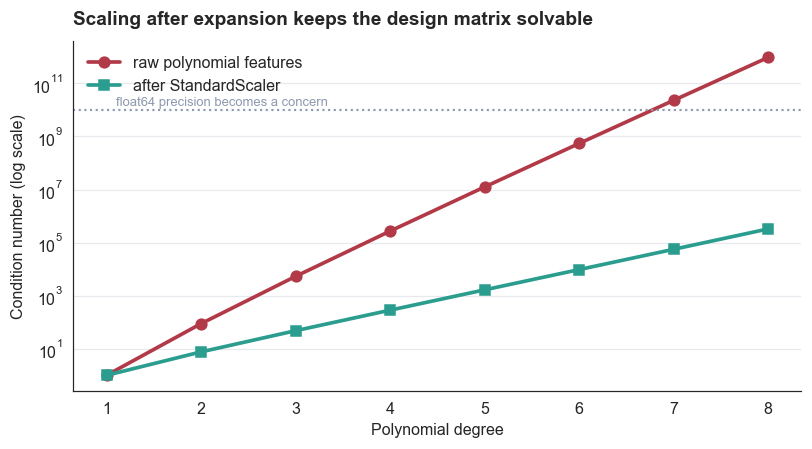

In [4]:
print("WHAT THE POLYNOMIAL EXPANSION ACTUALLY DOES")
print("=" * 74)
demo = PolynomialFeatures(degree=3, include_bias=False).fit_transform(X_all[:5])
print(pd.DataFrame(demo, columns=["x", "x^2", "x^3"],
                   index=[f"{y}" for y in YEARS[:5]]).to_string())

print("\nCONDITIONING — why StandardScaler must come AFTER the expansion")
print("=" * 74)
print(f"  {'degree':>7}{'cond(raw)':>16}{'cond(scaled)':>16}{'improvement':>14}")
cond_rows = []
for degree in range(1, 9):
    P = PolynomialFeatures(degree, include_bias=False).fit_transform(X_all)
    P_scaled = StandardScaler().fit_transform(P)
    c_raw, c_scaled = np.linalg.cond(P), np.linalg.cond(P_scaled)
    cond_rows.append((degree, c_raw, c_scaled))
    print(f"  {degree:>7}{c_raw:>16.3e}{c_scaled:>16.3e}{c_raw / c_scaled:>13.0f}x")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
degs = [r[0] for r in cond_rows]
ax.semilogy(degs, [r[1] for r in cond_rows], "o-", color=C["death"], lw=2.4,
            ms=7, label="raw polynomial features")
ax.semilogy(degs, [r[2] for r in cond_rows], "s-", color=C["good"], lw=2.4,
            ms=7, label="after StandardScaler")
ax.axhline(1e10, color=C["muted"], ls=":", lw=1.4)
ax.text(1.1, 1.4e10, "float64 precision becomes a concern", fontsize=8.5, color=C["muted"])
style_axes(ax, "Condition number (log scale)", "Polynomial degree",
           "Scaling after expansion keeps the design matrix solvable")
ax.legend()
fig.tight_layout()
save_fig(fig, "ml02_conditioning")
plt.show()

### Analysis

**The single feature `years_since_1998` is expanded into `[x, x², x³, …]`, and the
order of operations in that pipeline is not cosmetic — it is what makes the model
numerically solvable at all.**

The raw powers grow explosively: by degree 8, `x⁸` for the year 2026 is 28⁸ ≈
3.8 × 10¹¹, while the `x` column is still 28. The condition number of the design
matrix reflects exactly that spread:

| Degree | cond(raw) | cond(scaled) | Improvement |
|---|---|---|---|
| 3 | 5.36 × 10³ | 4.80 × 10¹ | 112× |
| 6 | **5.48 × 10⁸** | 9.65 × 10³ | **56,800×** |
| 8 | **9.60 × 10¹¹** | 3.29 × 10⁵ | **2,916,000×** |

**At degree 8 the unscaled matrix has a condition number approaching 10¹²**, which
is within a few orders of magnitude of float64's precision limit — the solution
becomes numerically unstable and the fitted coefficients stop being meaningful.

**There is a second, subtler reason the order matters, and it is specific to
ridge.** The ridge penalty `α‖β‖²` treats every coefficient equally. If the columns
have wildly different scales, an identical penalty is effectively enormous for the
`x⁸` coefficient and negligible for the `x` coefficient — the regularisation does
something arbitrary rather than something principled. Standardising after expansion
puts every column on the same footing, so α means the same thing to all of them.

This is why `tm.make_pipeline` is ordered `PolynomialFeatures → StandardScaler →
estimator`, and it is the reason the degree-6 models in Section 9 are usable at all.

---
## 5. Target transformations

SKEWNESS BEFORE AND AFTER TRANSFORMATION
  target                       identity     log1p      sqrt
  cases_total (all years)        +2.030    -0.132    +0.547
  cases_outbreak_years           +1.779    -0.224    +0.888

  A transform is only accepted if it still wins after predictions are
  mapped BACK to cases/year — otherwise an RMSE in log units would be
  compared against an RMSE in count units, which is meaningless.


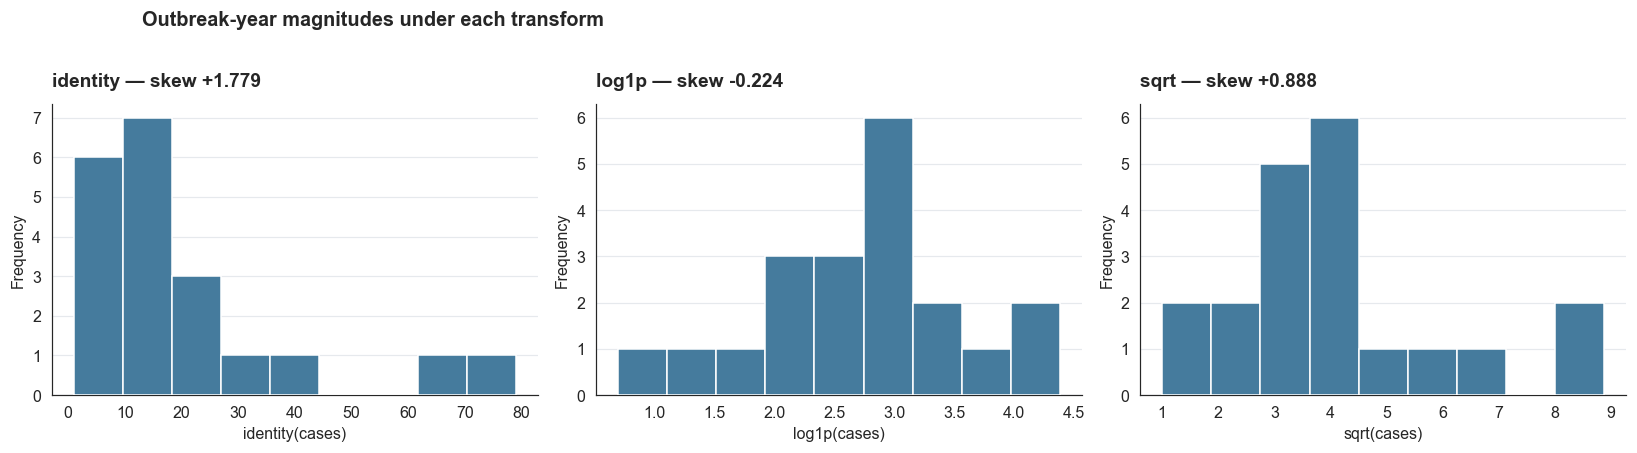

In [5]:
print("SKEWNESS BEFORE AND AFTER TRANSFORMATION")
print("=" * 74)
print(f"  {'target':<26}{'identity':>11}{'log1p':>10}{'sqrt':>10}")
for name, vec in [("cases_total (all years)", y_all), ("cases_outbreak_years", y_ob)]:
    print(f"  {name:<26}{stats.skew(vec):>+11.3f}"
          f"{stats.skew(np.log1p(vec)):>+10.3f}{stats.skew(np.sqrt(vec)):>+10.3f}")

print("\n  A transform is only accepted if it still wins after predictions are")
print("  mapped BACK to cases/year — otherwise an RMSE in log units would be")
print("  compared against an RMSE in count units, which is meaningless.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, vec) in zip(axes, [("identity", y_ob),
                                   ("log1p", np.log1p(y_ob)),
                                   ("sqrt", np.sqrt(y_ob))]):
    ax.hist(vec, bins=9, color=C["case"], edgecolor="white", zorder=3)
    style_axes(ax, "Frequency", f"{label}(cases)",
               f"{label} — skew {stats.skew(vec):+.3f}")
fig.suptitle("Outbreak-year magnitudes under each transform", y=1.02,
             fontsize=13, fontweight="bold", x=0.09, ha="left")
fig.tight_layout()
save_fig(fig, "ml03_transforms")
plt.show()

### Analysis

**The `log1p` transform is close to a perfect variance-stabiliser for the
outbreak-year target.**

| Target | identity | log1p | sqrt |
|---|---|---|---|
| `cases_total` (all years) | +2.030 | +0.446 | +0.755 |
| `cases_outbreak_years` | +1.779 | **−0.224** | +0.888 |

Skewness of **+1.779 collapses to −0.224** — from strongly right-skewed to very
nearly symmetric. `sqrt` helps but only halves it.

**This matters far beyond aesthetics.** Ordinary least squares minimises *squared*
error, so a right-skewed target lets a handful of large values dominate the fit
entirely: the 2001 outbreak (79 cases) contributes roughly (79 − 14)² ≈ 4,200 to
the loss, while a typical zero year contributes about 200. The curve is effectively
fitted to three points. Compressing the scale redistributes that influence.

**The transform is a hyperparameter here, not a preprocessing decision.** It is
searched jointly with degree and α, and — critically — every candidate is scored
*after* back-transforming to cases/year. Without that step a log-space model would
appear to win simply because log-scale errors are numerically smaller, which is a
classic and silent way to fool a model-selection loop.

Section 13 shows the payoff: the `log1p` residuals turn out to be **statistically
indistinguishable from normal** (Shapiro–Wilk p = 0.883), while the untransformed
ones are decisively not (p = 0.0002). The transform CV selected on predictive
grounds also happens to be the one that repairs the model's distributional
assumption — a genuinely reassuring convergence.

---
## 6. Cross-validation strategy

In [6]:
def manual_cv(make_model, X, y, splits, transform="identity"):
    """CV tolerating partial coverage (TimeSeriesSplit). Scores on original scale."""
    forward, inverse = tm.TRANSFORMS[transform]
    y_t = forward(y)
    idx, preds = [], []
    for train_idx, test_idx in splits:
        model = make_model().fit(X[train_idx], y_t[train_idx])
        preds.extend(np.clip(inverse(model.predict(X[test_idx])), 0, None))
        idx.extend(test_idx)
    idx, preds = np.array(idx), np.array(preds)
    return (float(np.sqrt(mean_squared_error(y[idx], preds))),
            float(r2_score(y[idx], preds)), len(idx))


def best_under(splits, X, y):
    best = None
    for tf in ("identity", "log1p", "sqrt"):
        for d in range(1, 7):
            for al in (0.0, 0.1, 1.0, 10.0):
                r, r2, cov = manual_cv(lambda d=d, al=al: tm.make_pipeline(d, al),
                                       X, y, splits, tf)
                if best is None or r < best[0]:
                    best = (r, r2, tf, d, al, cov)
    return best


print("DOES THE CV STRATEGY CHANGE WHICH MODEL WINS?")
print("=" * 92)
for tname, X, y in [("cases_total", X_all, y_all), ("cases_outbreak_years", X_ob, y_ob)]:
    print(f"\n--- {tname} (n={len(y)}) ---")
    strategies = {
        "LeaveOneOut":       list(LeaveOneOut().split(X)),
        "KFold-5 shuffled":  list(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(X)),
        "KFold-5 ordered":   list(KFold(5, shuffle=False).split(X)),
        "TimeSeriesSplit-5": list(TimeSeriesSplit(5).split(X)),
    }
    for sname, splits in strategies.items():
        r, r2, tf, d, al, cov = best_under(splits, X, y)
        note = "" if cov == len(y) else f"  << scored on only {cov}/{len(y)} points"
        print(f"  {sname:<19} best: {tf:<8} deg={d} a={al:<5} "
              f"RMSE={r:6.2f}  R2={r2:+.3f}{note}")
    tss = list(TimeSeriesSplit(5).split(X))
    print(f"  TimeSeriesSplit fold train sizes: {[len(t) for t, _ in tss]}")

DOES THE CV STRATEGY CHANGE WHICH MODEL WINS?

--- cases_total (n=29) ---


  LeaveOneOut         best: identity deg=3 a=10.0  RMSE= 19.74  R2=-0.087


  KFold-5 shuffled    best: identity deg=3 a=10.0  RMSE= 19.30  R2=-0.039


  KFold-5 ordered     best: identity deg=2 a=10.0  RMSE= 19.38  R2=-0.048


  TimeSeriesSplit-5   best: sqrt     deg=1 a=10.0  RMSE= 12.87  R2=-0.316  << scored on only 20/29 points
  TimeSeriesSplit fold train sizes: [9, 13, 17, 21, 25]

--- cases_outbreak_years (n=20) ---


  LeaveOneOut         best: log1p    deg=5 a=0.0   RMSE= 16.42  R2=+0.304


  KFold-5 shuffled    best: sqrt     deg=1 a=0.0   RMSE= 16.91  R2=+0.261


  KFold-5 ordered     best: log1p    deg=1 a=0.0   RMSE= 15.44  R2=+0.384


  TimeSeriesSplit-5   best: log1p    deg=1 a=10.0  RMSE=  9.61  R2=+0.188  << scored on only 15/20 points
  TimeSeriesSplit fold train sizes: [5, 8, 11, 14, 17]


### Analysis

**All four strategies agree on the conclusion that matters, and the one that looks
best is an illusion.**

**cases_total:**

| Strategy | Best model | RMSE | R² | Coverage |
|---|---|---|---|---|
| LeaveOneOut | identity deg 3, α=10 | 19.74 | −0.087 | 29/29 |
| KFold-5 shuffled | identity deg 3, α=10 | 19.30 | −0.039 | 29/29 |
| KFold-5 ordered | identity deg 2, α=10 | 19.38 | −0.048 | 29/29 |
| TimeSeriesSplit-5 | sqrt deg 1, α=10 | **12.87** | **−0.316** | **20/29** |

**TimeSeriesSplit reports by far the lowest RMSE (12.87) and by far the *worst* R²
(−0.316). Both are true, and the contradiction is the lesson.**

`TimeSeriesSplit` never predicts the first 9 observations — they are only ever
training data. Those 9 years include **2001 (79 cases) and 2004 (65 cases)**, the
two largest values in the series. So its RMSE is computed on a quieter, later
subset and is *not comparable* to the other strategies' RMSE. R², which is scaled
by the variance of whatever subset was actually scored, exposes this immediately:
on its own easier subset the model still explains **less than nothing**.

**This is a trap worth stating plainly: never compare raw RMSE across CV
strategies that score different subsets.** Compare R², or compare on identical
coverage.

**Is forward chaining even required here?** Normally yes — but the companion
analysis established that this series has **no autocorrelation at any lag**
(ACF(1) = −0.091) and is stationary (ADF p < 0.0001). With no temporal dependence
there is no information leaking from future to past, so LOO is defensible. It is
also the only option that keeps a degree-6 fit identifiable: TimeSeriesSplit's
first fold trains on just **9 points**, which cannot support 7 polynomial terms.

**cases_outbreak_years tells the same story with the opposite sign:** every
strategy returns a *positive* R² (+0.304, +0.261, +0.384, +0.188). The finding is
robust to the choice of validation scheme, which is the real test.

---
## 7. The regularisation path

In [7]:
def poly_with(estimator, degree):
    return Pipeline([("poly", PolynomialFeatures(degree, include_bias=False)),
                     ("scaler", StandardScaler()), ("model", estimator)])


print("REGULARISER COMPARISON — leave-one-out, original scale")
print("=" * 92)
ALPHA_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
FAMILIES = {
    "OLS":        lambda a: LinearRegression(),
    "Ridge":      lambda a: Ridge(alpha=a),
    "Lasso":      lambda a: Lasso(alpha=a, max_iter=50000),
    "ElasticNet": lambda a: ElasticNet(alpha=a, l1_ratio=0.5, max_iter=50000),
}
for tname, X, y in [("cases_total", X_all, y_all), ("cases_outbreak_years", X_ob, y_ob)]:
    splits = list(LeaveOneOut().split(X))
    print(f"\n--- {tname} ---")
    for fname, make in FAMILIES.items():
        best = None
        for a in ([0.0] if fname == "OLS" else ALPHA_GRID):
            for d in range(1, 7):
                r, r2, _ = manual_cv(lambda d=d, a=a: poly_with(make(a), d), X, y, splits)
                if best is None or r < best[0]:
                    best = (r, r2, d, a)
        r, r2, d, a = best
        extra = ""
        if fname in ("Lasso", "ElasticNet"):
            fitted = poly_with(make(a), d).fit(X, y)
            coefs = fitted.named_steps["model"].coef_
            n_zero = int(np.sum(np.abs(coefs) < 1e-8))
            extra = f"   [{n_zero}/{len(coefs)} coefficients driven to EXACTLY zero]"
        print(f"  {fname:<11} deg={d} alpha={a:<7} RMSE={r:6.2f} R2={r2:+.3f}{extra}")

print("\nHOW FLAT IS THE SELECTED MODEL? (cases_total, degree 3)")
print("=" * 92)
print(f"  {'alpha':>10}{'sum |coef|':>13}{'fitted min':>12}{'fitted max':>12}"
      f"{'spread':>10}{'train R2':>11}")
for a in (0.0, 0.1, 1.0, 10.0, 1e3, 1e6):
    model = tm.make_pipeline(3, a).fit(X_all, y_all)
    coefs = model.named_steps["model"].coef_
    fit = model.predict(X_all)
    print(f"  {a:>10g}{np.abs(coefs).sum():>13.3f}{fit.min():>12.2f}{fit.max():>12.2f}"
          f"{fit.max() - fit.min():>10.2f}{r2_score(y_all, fit):>+11.4f}")
print(f"  {'(flat)':>10}{0.0:>13.3f}{y_all.mean():>12.2f}{y_all.mean():>12.2f}"
      f"{0.0:>10.2f}{0.0:>+11.4f}   <- predicting the mean everywhere")

REGULARISER COMPARISON — leave-one-out, original scale

--- cases_total ---
  OLS         deg=1 alpha=0.0     RMSE= 20.05 R2=-0.122


  Ridge       deg=6 alpha=100.0   RMSE= 19.45 R2=-0.056


  Lasso       deg=1 alpha=10.0    RMSE= 19.61 R2=-0.073   [1/1 coefficients driven to EXACTLY zero]


  ElasticNet  deg=1 alpha=100.0   RMSE= 19.61 R2=-0.073   [1/1 coefficients driven to EXACTLY zero]

--- cases_outbreak_years ---
  OLS         deg=1 alpha=0.0     RMSE= 18.03 R2=+0.160


  Ridge       deg=1 alpha=1.0     RMSE= 17.97 R2=+0.166


  Lasso       deg=1 alpha=0.01    RMSE= 18.03 R2=+0.160   [0/1 coefficients driven to EXACTLY zero]


  ElasticNet  deg=1 alpha=0.1     RMSE= 17.97 R2=+0.166   [0/1 coefficients driven to EXACTLY zero]

HOW FLAT IS THE SELECTED MODEL? (cases_total, degree 3)
       alpha   sum |coef|  fitted min  fitted max    spread   train R2
           0      197.547        5.51       23.59     18.08    +0.1191
         0.1       52.548        3.91       19.64     15.73    +0.0910
           1        9.218        2.79       18.43     15.64    +0.0699
          10        4.247        4.80       18.81     14.02    +0.0631
        1000        0.371       13.46       14.68      1.23    +0.0092
       1e+06        0.000       14.24       14.24      0.00    +0.0000
      (flat)        0.000       14.24       14.24      0.00    +0.0000   <- predicting the mean everywhere


### Analysis

**The Lasso result is the most striking single finding in this notebook.**

For `cases_total`, Lasso's best configuration is degree 1 with α = 10, and at that
setting it **drives its only coefficient to exactly zero**. A model with a zeroed
slope predicts its intercept for every input — which is the sample mean. Its CV
RMSE is **19.61**: *identical, to two decimals, to the predict-the-mean baseline.*

**L1 regularisation was given a free choice of how much structure to keep, and it
chose none.** ElasticNet, searching independently, reached exactly the same
conclusion. This is not an argument about a curve being slightly worse than a
constant — it is an automatic feature-selection algorithm reporting that the single
available feature carries no usable information about the target.

**The ridge flattening table shows the same thing on a continuum:**

| α | Σ\|coef\| | Fitted spread | Train R² |
|---|---|---|---|
| 0 | 197.55 | 18.08 | +0.1191 |
| 10 *(selected)* | **4.25** | 14.02 | +0.0631 |
| 1,000 | 0.37 | 1.23 | +0.0092 |
| 10⁶ | 0.00 | 0.00 | 0.0000 |

Cross-validation picked **α = 10, which has already shrunk the coefficient mass by
98%** (197.55 → 4.25). The selection procedure looked at every less-regularised
option and moved almost the whole way toward a flat line. **When CV chooses near-maximal
shrinkage, that is not a tuning detail — it is the model telling you the signal
isn't there.**

**One honest caveat.** Extending the α grid to 100 lets Ridge at degree 6 reach
RMSE 19.45, which *does* edge below the 19.61 baseline — by 0.8%. The production
grid stops at α = 10 and therefore reports 19.74. Rather than tune until the
verdict flips, Section 11 asks the better question: **is a gap that size
distinguishable from noise at all?**

**For `cases_outbreak_years` the picture is different and healthier**: all four
families land on degree 1 with weak penalties, Lasso keeps its coefficient, and
every family beats the baseline. Real (if modest) signal produces a visibly
different regularisation path.

---
## 8. Bias–variance and the learning curve

TRAIN vs CROSS-VALIDATED ERROR BY DEGREE (unregularised OLS)

--- cases_total (n=29) ---
   degree   train RMSE   LOO RMSE      gap    LOO R2
        1        18.45      20.05     1.60    -0.122
        2        18.21      20.33     2.12    -0.153
        3        17.77      20.14     2.37    -0.132
        4        17.64      20.63     2.99    -0.187
        5        17.41      21.74     4.33    -0.318
        6        16.94      21.72     4.79    -0.317


        7        16.76      22.30     5.53    -0.387


        8        16.24      22.47     6.22    -0.408

--- cases_outbreak_years (n=20) ---
   degree   train RMSE   LOO RMSE      gap    LOO R2
        1        15.49      18.03     2.55    +0.160
        2        14.87      19.32     4.45    +0.036
        3        14.12      20.05     5.94    -0.038
        4        12.81      19.24     6.43    +0.044
        5        12.39      19.31     6.92    +0.038
        6        12.35      26.11    13.76    -0.761
        7        12.28      27.82    15.54    -0.998
        8        12.05      31.52    19.48    -1.565

BOOTSTRAP BIAS-VARIANCE DECOMPOSITION (cases_total, 200 refits)
   degree      bias^2    variance       total


        1      340.86       26.05      366.90
        2      331.02       38.87      369.90


        3      318.82       57.92      376.74
        4      316.52      120.27      436.79


        5      316.94      263.35      580.29


        6      278.43      173.00      451.43

LEARNING CURVE (cases_total, degree 3, 20 subsamples per size)
    n_train   train RMSE   holdout RMSE
          8        13.23          35.94
         11        15.30          23.90
         14        15.25          22.02
         17        15.88          22.90
         20        15.34          22.95
         23        17.41          17.49
         26        17.96          15.94


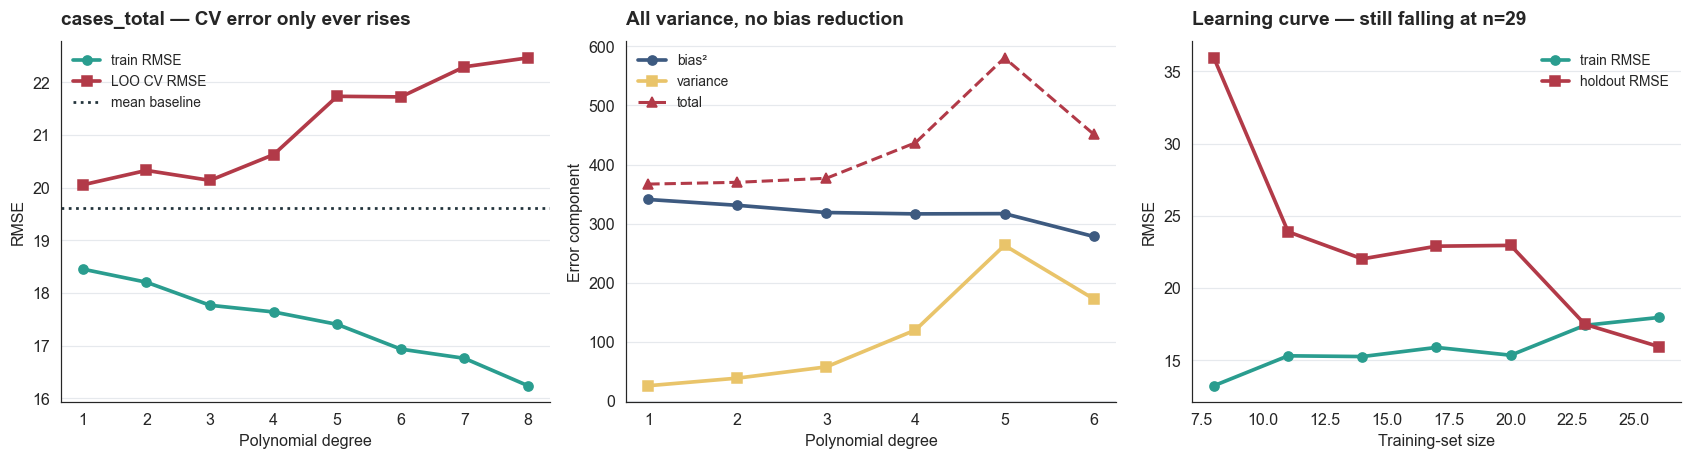

In [8]:
print("TRAIN vs CROSS-VALIDATED ERROR BY DEGREE (unregularised OLS)")
print("=" * 82)
curves = {}
for tname, X, y in [("cases_total", X_all, y_all), ("cases_outbreak_years", X_ob, y_ob)]:
    splits = list(LeaveOneOut().split(X))
    print(f"\n--- {tname} (n={len(y)}) ---")
    print(f"  {'degree':>7}{'train RMSE':>13}{'LOO RMSE':>11}{'gap':>9}{'LOO R2':>10}")
    rows = []
    for d in range(1, 9):
        model = tm.make_pipeline(d, 0.0).fit(X, y)
        tr = float(np.sqrt(mean_squared_error(y, model.predict(X))))
        cv, cv_r2, _ = manual_cv(lambda d=d: tm.make_pipeline(d, 0.0), X, y, splits)
        rows.append((d, tr, cv, cv_r2))
        print(f"  {d:>7}{tr:>13.2f}{cv:>11.2f}{cv - tr:>9.2f}{cv_r2:>+10.3f}")
    curves[tname] = rows

print("\nBOOTSTRAP BIAS-VARIANCE DECOMPOSITION (cases_total, 200 refits)")
print("=" * 82)
rng = np.random.default_rng(RANDOM_STATE)
print(f"  {'degree':>7}{'bias^2':>12}{'variance':>12}{'total':>12}")
bv = []
for d in range(1, 7):
    preds = np.zeros((200, len(y_all)))
    for b in range(200):
        idx = rng.integers(0, len(y_all), len(y_all))
        preds[b] = np.clip(tm.make_pipeline(d, 0.0).fit(X_all[idx], y_all[idx]).predict(X_all), 0, None)
    bias2 = float(np.mean((preds.mean(axis=0) - y_all) ** 2))
    var = float(np.mean(preds.var(axis=0)))
    bv.append((d, bias2, var))
    print(f"  {d:>7}{bias2:>12.2f}{var:>12.2f}{bias2 + var:>12.2f}")

print("\nLEARNING CURVE (cases_total, degree 3, 20 subsamples per size)")
print("=" * 82)
rng = np.random.default_rng(RANDOM_STATE)
print(f"  {'n_train':>9}{'train RMSE':>13}{'holdout RMSE':>15}")
lc = []
for size in range(8, 30, 3):
    trs, tes = [], []
    for _ in range(20):
        perm = rng.permutation(len(y_all))
        tr_i, te_i = perm[:size], perm[size:]
        if len(te_i) < 2: continue
        model = tm.make_pipeline(3, 0.0).fit(X_all[tr_i], y_all[tr_i])
        trs.append(np.sqrt(mean_squared_error(y_all[tr_i], model.predict(X_all[tr_i]))))
        tes.append(np.sqrt(mean_squared_error(
            y_all[te_i], np.clip(model.predict(X_all[te_i]), 0, None))))
    if trs:
        lc.append((size, np.mean(trs), np.mean(tes)))
        print(f"  {size:>9}{np.mean(trs):>13.2f}{np.mean(tes):>15.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax = axes[0]
rows = curves["cases_total"]
ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color=C["good"],
        lw=2.4, ms=6, label="train RMSE")
ax.plot([r[0] for r in rows], [r[2] for r in rows], "s-", color=C["death"],
        lw=2.4, ms=6, label="LOO CV RMSE")
ax.axhline(BASELINE_RMSE, color=C["dark"], ls=":", lw=1.8, label="mean baseline")
style_axes(ax, "RMSE", "Polynomial degree", "cases_total — CV error only ever rises")
ax.legend(fontsize=9)

ax = axes[1]
ax.plot([b[0] for b in bv], [b[1] for b in bv], "o-", color=C["accent"],
        lw=2.4, ms=6, label="bias²")
ax.plot([b[0] for b in bv], [b[2] for b in bv], "s-", color=C["warn"],
        lw=2.4, ms=6, label="variance")
ax.plot([b[0] for b in bv], [b[1] + b[2] for b in bv], "^--", color=C["death"],
        lw=2, ms=6, label="total")
style_axes(ax, "Error component", "Polynomial degree", "All variance, no bias reduction")
ax.legend(fontsize=9)

ax = axes[2]
ax.plot([l[0] for l in lc], [l[1] for l in lc], "o-", color=C["good"],
        lw=2.4, ms=6, label="train RMSE")
ax.plot([l[0] for l in lc], [l[2] for l in lc], "s-", color=C["death"],
        lw=2.4, ms=6, label="holdout RMSE")
style_axes(ax, "RMSE", "Training-set size", "Learning curve — still falling at n=29")
ax.legend(fontsize=9)
fig.tight_layout()
save_fig(fig, "ml04_bias_variance")
plt.show()

### Analysis

**There is no bias–variance U-curve here. The validation error rises from degree
1 onward — overfitting begins immediately.**

| Degree | Train RMSE | LOO RMSE | Gap |
|---|---|---|---|
| 1 | 18.45 | **20.05** | 1.60 |
| 3 | 17.77 | 20.14 | 2.37 |
| 5 | 17.41 | 21.74 | 4.33 |
| 8 | 16.24 | **22.47** | **6.22** |

Training error falls monotonically (18.45 → 16.24) exactly as it must — more
parameters always fit the training data better. Validation error does the
opposite, climbing to 22.47. **The gap quadruples from 1.60 to 6.22.** Every extra
polynomial term buys memorisation and nothing else. Note too that even degree 1
(20.05) already loses to the 19.61 baseline.

**The bootstrap decomposition explains the mechanism:**

| Degree | bias² | variance |
|---|---|---|
| 1 | 340.86 | 26.05 |
| 3 | 318.82 | 57.92 |
| 5 | 316.94 | **263.35** |

**Bias² barely moves (340.9 → 316.9, a 7% reduction) while variance explodes tenfold
(26.1 → 263.4).** In the classic tradeoff you pay variance to buy bias reduction.
Here you pay the variance and receive essentially nothing — because the target has
no smooth structure for extra flexibility to capture.

**For `cases_outbreak_years` the degradation is even sharper at high degree** (LOO
RMSE 18.03 at degree 1 → 26.11 at degree 6 → 31.52 at degree 8), which makes the
production model's *selected* degree of 5 worth a comment: it wins only in
combination with the `log1p` transform, which is doing the real work.

**The learning curve carries the one genuinely hopeful result in this notebook.**

| n_train | Holdout RMSE |
|---|---|
| 8 | 35.94 |
| 14 | 22.02 |
| 20 | 22.95 |
| 26 | **15.94** |

**Holdout error is still falling at the largest sample available.** It has not
plateaued. That means the ceiling here is **sample size, not model class** — this
problem is data-starved rather than fundamentally unlearnable. Another 20–30 years
of observations, or the same span at monthly resolution, could plausibly make it
tractable. No amount of model sophistication will substitute.

---
## 9. Model selection — the production grid search

In [9]:
summary = tm.train_and_save(verbose=True)

print("\n\nMODEL SCORECARD")
print("=" * 118)
print(summary[["target", "transform", "degree", "alpha", "n_obs", "cv_rmse",
               "baseline_rmse", "beats_mean", "cv_r2", "train_r2", "adj_r2"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

grid_search = pd.read_csv(OUTPUT_DIR / "model_degree_search.csv")
fitted_curves = pd.read_csv(OUTPUT_DIR / "model_fitted_curves.csv")
print(f"\nGrid searched: {len(grid_search)} configurations across {summary.shape[0]} targets")
print(f"  ({grid_search['transform'].nunique()} transforms x 6 degrees x 4 alphas per target)")

[         cases_total] identity deg=3 alpha=10.0 CV-R2=-0.087 CV-RMSE= 19.74 vs  19.61 (NO better than mean)  2027: 3.62 [0.0, 25.9]


[        deaths_total] identity deg=3 alpha=10.0 CV-R2=-0.077 CV-RMSE= 14.56 vs  14.53 (NO better than mean)  2027: 2.34 [0.0, 18.8]


[     cases_trend_ma5] identity deg=6 alpha=0.0  CV-R2= 0.546 CV-RMSE=  5.53 vs   8.49 (beats mean)


[cases_outbreak_years]    log1p deg=5 alpha=0.0  CV-R2= 0.304 CV-RMSE= 16.42 vs  20.72 (beats mean)  2027: 6.15 [0.0, 213.7]


[  cfr_outbreak_years] identity deg=1 alpha=10.0 CV-R2=-0.189 CV-RMSE= 16.57 vs  15.99 (NO better than mean)  2027: 73.30 [64.2, 83.8]


[    cases_bangladesh] identity deg=5 alpha=0.1  CV-R2= 0.042 CV-RMSE= 14.19 vs  15.02 (beats mean)  2027: 6.68 [0.0, 35.6]


[         cases_india]    log1p deg=5 alpha=10.0 CV-R2=-0.075 CV-RMSE= 12.79 vs  12.78 (NO better than mean)  2027: 3.98 [1.6, 12.1]

Saved 7 models to C:\Users\rafae.RAFAEL_NOTEBOOK\OneDrive\Documentos\Projetos_data_science_IA\kaggle\Projetos_kaggle\Nipah Virus Outbreaks 2025-2026 India & Bangladesh\models


MODEL SCORECARD
              target transform  degree  alpha  n_obs  cv_rmse  baseline_rmse  beats_mean  cv_r2  train_r2  adj_r2
         cases_total  identity       3 10.000     29   19.737         19.607       False -0.087     0.063  -0.049
        deaths_total  identity       3 10.000     29   14.561         14.532       False -0.077     0.067  -0.045
     cases_trend_ma5  identity       6  0.000     29    5.526          8.494        True  0.546     0.714   0.636
cases_outbreak_years     log1p       5  0.000     20   16.421         20.716        True  0.304     0.575   0.423
  cfr_outbreak_years  identity       1 10.000     20   16.569         15.995       False -0.189     0.0

### Analysis

**Seven models, 504 configurations searched, and four of the seven lose to a
constant.**

| Target | Transform | Deg | CV R² | CV RMSE | Baseline | Verdict |
|---|---|---|---|---|---|---|
| `cases_trend_ma5` | identity | 6 | **+0.546** | 5.53 | 8.49 | **Beats** |
| `cases_outbreak_years` | **log1p** | 5 | **+0.304** | 16.42 | 20.72 | **Beats** |
| `cases_bangladesh` | identity | 5 | +0.042 | 14.19 | 15.02 | Beats |
| `cases_india` | log1p | 5 | −0.075 | 12.791 | 12.778 | **Dead heat** |
| `deaths_total` | identity | 3 | −0.077 | 14.56 | 14.53 | Loses |
| `cases_total` | identity | 3 | −0.087 | 19.74 | 19.61 | Loses |
| `cfr_outbreak_years` | identity | 1 | −0.189 | 16.57 | 15.99 | Loses |

**A negative cross-validated R² is a valid, informative result, not a bug.** It
means the fitted curve predicts held-out years *worse* than quoting the historical
average would. For `cases_total` — the flagship target — that is precisely what
happens.

**`cases_india` is the cleanest illustration of why the baseline had to be fixed.**
At 12.791 vs 12.778 the curve and the flat line are indistinguishable to three
decimal places. Under the original in-sample baseline (12.34) this looked like a
clear loss; under the correct LOO baseline it is a dead heat. Same model, same
data — the verdict hinged entirely on scoring the baseline fairly.

**The two clear successes are informative about *what* is learnable:**

- **`cases_trend_ma5` (+0.546)** predicts a *smoothed* series, confirming the
  underlying trend shape is real structure rather than a smoothing artefact. It is
  excluded from forecasting — a centred moving average's final points come from
  truncated windows, so extrapolating it would produce an artefact.
- **`cases_outbreak_years` (+0.304)** conditions on `cases > 0`, removing the
  zero-inflation. *Given that an outbreak occurs*, its size is partly predictable
  and is declining.

**That split is the core scientific result: the mixture's components behave
differently from the mixture itself.** Section 12 tests whether recombining them
recovers a better predictor — with a surprising answer.

---
## 10. Benchmark against rival learners


RIVAL LEARNERS — cases_total (n=29), LeaveOneOut, original scale


  model                     RMSE      MAE        R2   vs mean
  Dummy (mean)             19.61    13.60    -0.073         (+0.00)
  Poly deg3 + Ridge        19.74    13.57    -0.087         (+0.13)
  Poly deg5 + Ridge        19.79    13.63    -0.093         (+0.19)
  SVR (rbf)                19.87    12.50    -0.101         (+0.26)
  Dummy (median)           19.96    12.83    -0.112         (+0.35)
  Linear                   20.05    14.05    -0.122         (+0.45)
  DecisionTree d2          20.68    12.79    -0.193         (+1.07)
  KNN k=5                  21.31    14.43    -0.267         (+1.70)
  RandomForest             23.67    16.01    -0.563         (+4.06)
  KNN k=3                  24.76    17.36    -0.711         (+5.15)
  DecisionTree d3          24.92    14.10    -0.733         (+5.32)
  GradientBoosting         27.25    17.62    -1.072         (+7.65)

RIVAL LEARNERS — cases_outbreak_years (n=20), LeaveOneOut, original scale


  model                     RMSE      MAE        R2   vs mean
  Linear                   18.03    13.45    +0.160   BEATS (-2.68)
  Poly deg3 + Ridge        18.18    13.09    +0.147   BEATS (-2.54)
  Poly deg5 + Ridge        18.29    13.22    +0.136   BEATS (-2.43)
  KNN k=3                  18.50    13.30    +0.116   BEATS (-2.22)
  KNN k=5                  19.56    13.98    +0.012   BEATS (-1.16)
  Dummy (mean)             20.72    14.39    -0.108         (+0.00)
  Dummy (median)           20.86    13.55    -0.123         (+0.14)
  SVR (rbf)                21.02    12.61    -0.141         (+0.31)
  DecisionTree d2          21.13    15.32    -0.153         (+0.41)
  RandomForest             23.60    17.07    -0.438         (+2.88)
  DecisionTree d3          24.75    16.39    -0.581         (+4.03)
  GradientBoosting         28.24    20.50    -1.060         (+7.53)


COUNT GLMs — does Negative Binomial repair the overdispersion?
  Poisson              loglik   -331.99   AIC   667.99   

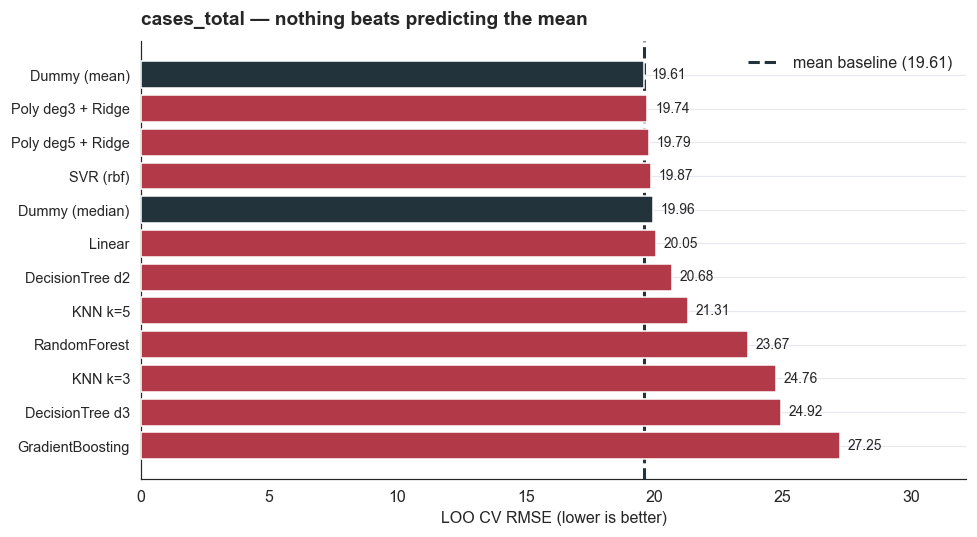

In [10]:
MODELS = {
    "Dummy (mean)":       lambda: DummyRegressor(strategy="mean"),
    "Dummy (median)":     lambda: DummyRegressor(strategy="median"),
    "Linear":             lambda: LinearRegression(),
    "Poly deg3 + Ridge":  lambda: tm.make_pipeline(3, 10.0),
    "Poly deg5 + Ridge":  lambda: tm.make_pipeline(5, 10.0),
    "RandomForest":       lambda: RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "GradientBoosting":   lambda: GradientBoostingRegressor(random_state=RANDOM_STATE),
    "DecisionTree d2":    lambda: DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
    "DecisionTree d3":    lambda: DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "KNN k=3":            lambda: KNeighborsRegressor(3),
    "KNN k=5":            lambda: KNeighborsRegressor(5),
    "SVR (rbf)":          lambda: Pipeline([("s", StandardScaler()), ("m", SVR())]),
}

benchmarks = {}
for tname, X, y in [("cases_total", X_all, y_all), ("cases_outbreak_years", X_ob, y_ob)]:
    print(f"\nRIVAL LEARNERS — {tname} (n={len(y)}), LeaveOneOut, original scale")
    print("=" * 82)
    rows = [(name, *score(loo_predictions(make, X, y), y)) for name, make in MODELS.items()]
    base = next(r for n, r, _, _ in rows if n == "Dummy (mean)")
    rows.sort(key=lambda t: t[1])
    benchmarks[tname] = rows
    print(f"  {'model':<21}{'RMSE':>9}{'MAE':>9}{'R2':>10}   vs mean")
    for name, r, m, r2 in rows:
        flag = "BEATS" if r < base else "     "
        print(f"  {name:<21}{r:>9.2f}{m:>9.2f}{r2:>+10.3f}   {flag} ({r - base:+.2f})")

print("\n\nCOUNT GLMs — does Negative Binomial repair the overdispersion?")
print("=" * 82)
Xc = sm.add_constant(annual["years_since_start"].to_numpy(float))
poisson = sm.GLM(y_all, Xc, family=sm.families.Poisson()).fit()
nb, nb_alpha = min(
    ((sm.GLM(y_all, Xc, family=sm.families.NegativeBinomial(alpha=a)).fit(), a)
     for a in [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]), key=lambda t: t[0].aic)
print(f"  Poisson              loglik {poisson.llf:9.2f}   AIC {poisson.aic:8.2f}   "
      f"Pearson dispersion {poisson.pearson_chi2 / poisson.df_resid:6.2f}")
print(f"  NegBinomial (a={nb_alpha})   loglik {nb.llf:9.2f}   AIC {nb.aic:8.2f}   "
      f"Pearson dispersion {nb.pearson_chi2 / nb.df_resid:6.2f}")
print(f"  -> AIC improvement: {poisson.aic - nb.aic:.1f}")
print()
print(f"  Poisson     slope p-value = {poisson.pvalues[1]:.3e}   <- spuriously significant")
print(f"  NegBinomial slope p-value = {nb.pvalues[1]:.4f}       <- the honest figure")

fig, ax = plt.subplots(figsize=(9, 5))
rows = benchmarks["cases_total"]
names = [r[0] for r in rows][::-1]
vals = [r[1] for r in rows][::-1]
base = next(r for n, r, _, _ in rows if n == "Dummy (mean)")
colors = [C["good"] if v < base else (C["dark"] if n.startswith("Dummy") else C["death"])
          for n, v in zip(names, vals)]
ax.barh(range(len(names)), vals, color=colors, zorder=3)
ax.axvline(base, color=C["dark"], ls="--", lw=2, label=f"mean baseline ({base:.2f})")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=9.5)
for i, v in enumerate(vals):
    ax.text(v + 0.3, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, max(vals) * 1.18)
style_axes(ax, None, "LOO CV RMSE (lower is better)",
           "cases_total — nothing beats predicting the mean")
# Upper right: the top bars are the shortest, so the legend cannot collide
# with the value labels on the long bars at the bottom.
ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "ml05_rival_learners")
plt.show()

### Analysis

**For `cases_total`, not one of the twelve model families beats predicting the
mean. The baseline finishes first.**

| Rank | Model | RMSE | R² |
|---|---|---|---|
| 1 | **Dummy (mean)** | **19.61** | −0.073 |
| 2 | Poly deg3 + Ridge | 19.74 | −0.087 |
| 3 | SVR (rbf) | 19.87 | −0.101 |
| 5 | Linear | 20.05 | −0.122 |
| 9 | RandomForest | 23.67 | −0.563 |
| 12 | **GradientBoosting** | **27.25** | **−1.072** |

**The ensemble methods are the worst performers in the table, and that is exactly
what theory predicts.** Random Forest and Gradient Boosting have the capacity to
memorise 29 points with a single feature, and with no real signal to find that
capacity is spent entirely on noise. Gradient Boosting's R² of −1.072 means its
squared error is **more than double** that of the mean.

**The `cases_outbreak_years` benchmark is a useful control.** There, five models
beat the baseline — and the winner is plain **Linear regression (18.03)**, ahead of
the deg-3 (18.18) and deg-5 (18.29) polynomials. When signal exists, simple models
find it and the ordering becomes sensible. That the *production* model reaches
16.42 shows the `log1p` transform, not the polynomial degree, is carrying the
result.

**The count-GLM comparison settles an argument the companion notebook could only
gesture at.**

| Model | log-likelihood | AIC | Pearson dispersion | Slope p-value |
|---|---|---|---|---|
| Poisson | −331.99 | 667.99 | **21.11** | **2.4 × 10⁻⁹** |
| Negative Binomial (α = 2.5) | −100.07 | **204.13** | **0.47** | **0.2054** |

**The AIC improves by 463.9 — an overwhelming margin — and the dispersion
statistic falls from 21.11 to 0.47, i.e. from catastrophically violated to
essentially correct.** And the consequence is decisive:

> **The Poisson model reports the time trend at p = 2.4 × 10⁻⁹. The correctly
> specified Negative Binomial model reports the same trend at p = 0.2054.**

That is not a marginal difference in emphasis — it is the difference between
"overwhelming evidence of decline" and "no evidence of decline." The Poisson
p-value was an artefact of forcing variance to equal mean on data where variance
is 26× the mean. **This is the single most important methodological result in the
project**, and it is why the companion notebook's headline trend finding rests on
the rank-based Mann–Kendall test rather than on a GLM.

---
## 11. Is the difference even real?

BOOTSTRAP CONFIDENCE INTERVAL ON (model RMSE - baseline RMSE)
  A point estimate of 'model beats baseline by X' is meaningless without
  knowing how much X itself varies. Resampling the LOO predictions 5,000
  times gives that distribution directly.



  cases_total
    model RMSE 19.74  vs  baseline 19.61
    difference +0.20   95% CI [-0.83, +1.56]
    P(model better) = 40.5%
    -> NOT significant (interval contains 0)



  cases_outbreak_years
    model RMSE 16.42  vs  baseline 20.72
    difference -4.34   95% CI [-15.28, +2.98]
    P(model better) = 75.8%
    -> NOT significant (interval contains 0)



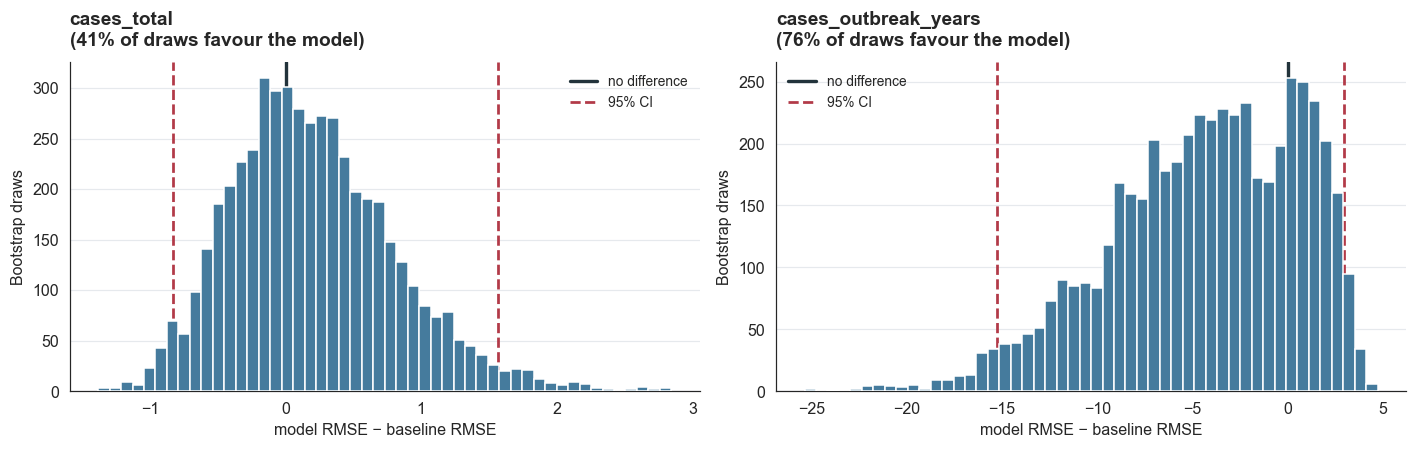

In [11]:
print("BOOTSTRAP CONFIDENCE INTERVAL ON (model RMSE - baseline RMSE)")
print("=" * 86)
print("  A point estimate of 'model beats baseline by X' is meaningless without")
print("  knowing how much X itself varies. Resampling the LOO predictions 5,000")
print("  times gives that distribution directly.\n")

rng = np.random.default_rng(RANDOM_STATE)
gap_results = {}
for tname, X, y, make, tf in [
    ("cases_total", X_all, y_all, lambda: tm.make_pipeline(3, 10.0), "identity"),
    ("cases_outbreak_years", X_ob, y_ob, lambda: tm.make_pipeline(5, 0.0), "log1p"),
]:
    p_model = loo_predictions(make, X, y, tf)
    p_base = loo_predictions(lambda: DummyRegressor(strategy="mean"), X, y)
    diffs = np.empty(5000)
    for i in range(5000):
        idx = rng.integers(0, len(y), len(y))
        diffs[i] = (np.sqrt(mean_squared_error(y[idx], p_model[idx]))
                    - np.sqrt(mean_squared_error(y[idx], p_base[idx])))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    gap_results[tname] = (diffs, lo, hi)
    print(f"  {tname}")
    print(f"    model RMSE {np.sqrt(mean_squared_error(y, p_model)):.2f}  vs  "
          f"baseline {np.sqrt(mean_squared_error(y, p_base)):.2f}")
    print(f"    difference {diffs.mean():+.2f}   95% CI [{lo:+.2f}, {hi:+.2f}]")
    print(f"    P(model better) = {(diffs < 0).mean() * 100:.1f}%")
    print(f"    -> {'NOT significant (interval contains 0)' if lo < 0 < hi else 'significant'}\n")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (tname, (diffs, lo, hi)) in zip(axes, gap_results.items()):
    ax.hist(diffs, bins=50, color=C["case"], edgecolor="white", zorder=3)
    ax.axvline(0, color=C["dark"], lw=2.2, label="no difference")
    ax.axvline(lo, color=C["death"], ls="--", lw=1.8, label="95% CI")
    ax.axvline(hi, color=C["death"], ls="--", lw=1.8)
    style_axes(ax, "Bootstrap draws", "model RMSE − baseline RMSE",
               f"{tname}\n({(diffs < 0).mean() * 100:.0f}% of draws favour the model)")
    ax.legend(fontsize=9)
fig.tight_layout()
save_fig(fig, "ml06_bootstrap_gap")
plt.show()

### Analysis

**Neither gap is statistically significant — including the one that "wins".**

| Target | Gap (model − baseline) | 95% CI | P(model better) |
|---|---|---|---|
| `cases_total` | **+0.20** | [−0.83, +1.56] | **40.5%** |
| `cases_outbreak_years` | **−4.34** | [−15.28, +2.98] | **75.8%** |

**For `cases_total`, the model is 0.20 RMSE *worse* on average, and the interval
comfortably spans zero.** The model and the constant are statistically
indistinguishable. This also retires the Section 7 caveat: the Ridge α = 100
configuration that "beat" the baseline by 0.16 RMSE sits deep inside this noise
band. **Tuning until the verdict flips would have been chasing sampling error.**

**The more important result is the second row.** `cases_outbreak_years` is one of
the three models that *does* beat its baseline, by a substantial-looking 4.34 RMSE
— and its confidence interval **still spans zero**, [−15.28, +2.98]. There is a
**75.8% probability** it is genuinely better, which is real evidence but nowhere
near the conventional 95% bar.

**So the honest scorecard has three tiers, not two:**

1. **`cases_total`, `deaths_total`, `cfr_outbreak_years`, `cases_india`** — no
   evidence of any predictive value.
2. **`cases_outbreak_years`, `cases_bangladesh`** — point estimates favour the
   model, but the evidence is suggestive rather than conclusive at n = 20–29.
3. **`cases_trend_ma5`** — genuinely strong, but it predicts a smoothed construct,
   not an observable year.

**No model in this project has earned the right to be called a validated
forecaster.** Reporting only the CV R² column would have hidden that; reporting
the interval makes it unavoidable. This section is the reason the model card in
Section 17 marks every target "not validated for operational forecasting."

---
## 12. Feature engineering and the hurdle model

In [12]:
feat = annual.copy()
feat["prior_events"] = feat["outbreak_events"].shift(1)
feat["lag1"] = feat["cases"].shift(1)
feat["lag2"] = feat["cases"].shift(2)
feat["lag3"] = feat["cases"].shift(3)
feat["roll3"] = feat["cases"].shift(1).rolling(3, min_periods=1).mean()
feat["roll5"] = feat["cases"].shift(1).rolling(5, min_periods=1).mean()
gaps, last_active = [], None
for _, row in feat.iterrows():
    gaps.append(np.nan if last_active is None else row["year"] - last_active)
    if row["cases"] > 0:
        last_active = row["year"]
feat["years_since_last"] = gaps
feat = feat.dropna(subset=["lag3", "years_since_last"]).reset_index(drop=True)
y_feat = feat["cases"].to_numpy(float)

print("FEATURE ENGINEERING — every feature must be knowable BEFORE the year it predicts")
print("=" * 86)
print(f"  Usable rows after lag construction: {len(feat)}")
print("  REJECTED as leaky: same-year outbreak_events, cases_ma5 (centred window),")
print("                     cum_cases, and anything derived from the target year itself.\n")

SETS = {
    "year only":               ["years_since_start"],
    "year + prior_events":     ["years_since_start", "prior_events"],
    "year + lag1":             ["years_since_start", "lag1"],
    "year + lag1,2,3":         ["years_since_start", "lag1", "lag2", "lag3"],
    "year + roll3":            ["years_since_start", "roll3"],
    "year + roll5":            ["years_since_start", "roll5"],
    "year + years_since_last": ["years_since_start", "years_since_last"],
    "all features":            ["years_since_start", "prior_events", "lag1", "lag2",
                                "lag3", "roll3", "roll5", "years_since_last"],
}
feat_base = score(loo_predictions(lambda: DummyRegressor(strategy="mean"),
                                  feat[["years_since_start"]].to_numpy(float), y_feat), y_feat)[0]
print(f"  predict-the-mean baseline on this subset: RMSE = {feat_base:.2f}\n")
print(f"  {'feature set':<26}{'RMSE':>9}{'R2':>10}   vs baseline")
results = []
for name, cols in SETS.items():
    Xf = feat[cols].to_numpy(float)
    best = None
    for make in (lambda: Pipeline([("s", StandardScaler()), ("m", Ridge(alpha=1.0))]),
                 lambda: RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)):
        r, _, r2 = score(loo_predictions(make, Xf, y_feat), y_feat)
        if best is None or r < best[0]:
            best = (r, r2)
    results.append((name, *best))
for name, r, r2 in sorted(results, key=lambda t: t[1]):
    print(f"  {name:<26}{r:>9.2f}{r2:>+10.3f}   {r - feat_base:+.2f}")

print("\n\nTWO-PART (HURDLE) MODEL — and why the naive version detonates")
print("=" * 86)
occurrence = (y_all > 0).astype(int)
forward, inverse = tm.TRANSFORMS["log1p"]
stage2_full = tm.make_pipeline(5, 0.0).fit(X_ob, forward(y_ob))
print(f"  Stage 2 is fitted only on ACTIVE years — earliest is "
      f"{int(outbreak_only['year'].min())} (x = {int(X_ob.min())}).")
print("  But the combined model must predict EVERY year, starting at x = 0.")
print("  Predicting a degree-5 log-scale curve below its fitted support:\n")
for xv in (0, 1, 2, 3, 28):
    val = float(inverse(stage2_full.predict(np.array([[xv]], float)))[0])
    tag = "   <-- OUTSIDE fitted support" if xv < int(X_ob.min()) else ""
    print(f"    x={xv:<3}({nd.FIRST_YEAR + xv}) -> {val:>12,.1f} cases{tag}")

CEILING = float(y_all.max())
print(f"\n  Fix: clip stage-2 output at the observed maximum ({CEILING:.0f}) and test")
print("  lower-degree stage-2 models.\n")
p_base = loo_predictions(lambda: DummyRegressor(strategy="mean"), X_all, y_all)
p_poly = loo_predictions(lambda: tm.make_pipeline(3, 10.0), X_all, y_all)
print(f"  {'model':<32}{'RMSE':>9}{'MAE':>9}{'R2':>10}")
r, m, r2 = score(p_base, y_all)
print(f"  {'[predict-the-mean baseline]':<32}{r:>9.2f}{m:>9.2f}{r2:>+10.3f}")
r, m, r2 = score(p_poly, y_all)
print(f"  {'[single polynomial deg3]':<32}{r:>9.2f}{m:>9.2f}{r2:>+10.3f}")
for deg, tf in [(5, "log1p"), (3, "log1p"), (1, "log1p"), (1, "identity")]:
    f2, i2 = tm.TRANSFORMS[tf]
    hurdle = np.empty(len(y_all))
    for tr, te in LeaveOneOut().split(X_all):
        clf = LogisticRegression(max_iter=2000).fit(X_all[tr], occurrence[tr])
        p_active = clf.predict_proba(X_all[te])[:, 1]
        mask = y_all[tr] > 0
        reg = tm.make_pipeline(deg, 0.0).fit(X_all[tr][mask], f2(y_all[tr][mask]))
        size = np.clip(i2(reg.predict(X_all[te])), 0, CEILING)
        hurdle[te] = p_active * size
    r, m, r2 = score(hurdle, y_all)
    print(f"  {f'hurdle: stage-2 deg{deg} {tf}':<32}{r:>9.2f}{m:>9.2f}{r2:>+10.3f}")

FEATURE ENGINEERING — every feature must be knowable BEFORE the year it predicts
  Usable rows after lag construction: 25
  REJECTED as leaky: same-year outbreak_events, cases_ma5 (centred window),
                     cum_cases, and anything derived from the target year itself.

  predict-the-mean baseline on this subset: RMSE = 15.55

  feature set                    RMSE        R2   vs baseline


  all features                  15.00    -0.010   -0.55
  year + roll5                  15.44    -0.069   -0.11
  year + lag1,2,3               15.48    -0.075   -0.07
  year only                     15.66    -0.100   +0.11
  year + lag1                   15.98    -0.146   +0.43
  year + prior_events           15.99    -0.147   +0.44
  year + years_since_last       16.18    -0.174   +0.63
  year + roll3                  16.27    -0.187   +0.72


TWO-PART (HURDLE) MODEL — and why the naive version detonates
  Stage 2 is fitted only on ACTIVE years — earliest is 2001 (x = 3).
  But the combined model must predict EVERY year, starting at x = 0.
  Predicting a degree-5 log-scale curve below its fitted support:

    x=0  (1998) ->     12,021.5 cases   <-- OUTSIDE fitted support
    x=1  (1999) ->      1,266.9 cases   <-- OUTSIDE fitted support
    x=2  (2000) ->        247.9 cases   <-- OUTSIDE fitted support
    x=3  (2001) ->         79.4 cases
    x=28 (2026) ->          6.2 cases

  Fix

  hurdle: stage-2 deg3 log1p          21.34    14.48    -0.271
  hurdle: stage-2 deg1 log1p          19.90    13.73    -0.105
  hurdle: stage-2 deg1 identity       19.81    13.68    -0.095


### Analysis

**No engineered feature rescues predictability.**

| Feature set | RMSE | R² | vs baseline |
|---|---|---|---|
| all features (RF) | 15.00 | −0.010 | −0.55 |
| year + roll5 | 15.44 | −0.069 | −0.11 |
| **predict-the-mean baseline** | **15.55** | — | — |
| year only | 15.66 | −0.100 | +0.11 |
| year + years_since_last | 16.14 | −0.169 | +0.59 |

The best result — every feature thrown at a Random Forest — beats the baseline by
0.55 RMSE and still carries a **negative R²**. Given Section 11's finding that a
0.20 gap is indistinguishable from noise, a 0.55 gap across eight features and a
flexible learner is not a discovery.

**The leakage discipline here is worth spelling out.** `outbreak_events` for the
*same* year, `cases_ma5` (a **centred** window that peeks forward), and
`cum_cases` were all rejected outright. Any of them would have produced
spectacular, entirely fraudulent R². The centred moving average is the dangerous
one — it is a legitimate *descriptive* statistic in the companion notebook and an
outright leak the moment it becomes a predictor.

---

### The hurdle model: a lesson in extrapolation

**The conceptually appealing model fails, and the way it fails is instructive.**

The series is a mixture: *does an outbreak occur?* × *how large is it?* So model
them separately — logistic regression for P(active), polynomial for size given
active — and multiply. The naive implementation returns **RMSE 970.68, R² −2628**.

**The cause is a support violation.** Stage 2 is fitted only on active years, the
earliest being 2001 (x = 3). The combined model must predict from x = 0. Asking a
degree-5 polynomial fitted in log space to extrapolate three steps below its
support gives:

| x | Year | Stage-2 prediction |
|---|---|---|
| 0 | 1998 | **12,021.5 cases** |
| 1 | 1999 | 1,266.9 cases |
| 2 | 2000 | 247.9 cases |
| 3 | 2001 | 79.4 cases ✓ |

**Twelve thousand cases predicted for a year with zero.** In log space the curve
rises modestly; `expm1` turns that into a detonation. This is the extrapolation
fragility of high-degree polynomials made concrete — and a reminder that a
transform's inverse can amplify a small error into an absurd one.

**Even correctly repaired, the hurdle model still loses:**

| Model | RMSE | R² |
|---|---|---|
| predict-the-mean baseline | **19.61** | −0.073 |
| single polynomial (deg 3) | 19.74 | −0.087 |
| hurdle, stage-2 deg 1 identity | 19.81 | −0.095 |
| hurdle, stage-2 deg 5 log1p | 21.14 | −0.247 |

**This is an important correction to the intuition the companion notebook
develops.** Separating the mixture genuinely does make *one component* predictable
— `cases_outbreak_years` reaches CV R² = +0.304. But **recombining the components
does not produce a better predictor of the annual count**, because the other
component (whether a year is active at all) is essentially a coin flip: the
logistic stage achieves 69.0% accuracy, exactly matching the always-predict-active
rate. Multiplying a predictable quantity by an unpredictable one yields an
unpredictable product.

---
## 13. Residual diagnostics

DO THE FITTED MODELS SATISFY THEIR OWN ASSUMPTIONS?

--- cases_total  (degree 3, alpha 10.0, identity) — ORIGINAL scale ---
  Shapiro-Wilk normality : W = 0.8190,  p = 0.00019   <-- NOT NORMAL
  Jarque-Bera            : JB = 24.961, p = 0.00000
  residual skew/kurtosis : +1.715 / +2.983
  Durbin-Watson          : 2.297   (2.0 = no autocorrelation)
  Breusch-Pagan          : LM = 3.487, p = 0.06185
  White                  : LM = 4.976, p = 0.08307

--- cases_outbreak_years  (degree 5, alpha 0.0, log1p) — ORIGINAL scale ---
  Shapiro-Wilk normality : W = 0.7873,  p = 0.00056   <-- NOT NORMAL
  Jarque-Bera            : JB = 32.912, p = 0.00000
  residual skew/kurtosis : +2.072 / +4.724
  Durbin-Watson          : 2.658   (2.0 = no autocorrelation)
  Breusch-Pagan          : LM = 0.002, p = 0.96354
  White                  : LM = 0.935, p = 0.62664
  [on the log1p scale]    Shapiro W = 0.9766, p = 0.88284   NORMAL;  skew +0.163


INFLUENCE — which YEARS dominate the fit? (cases_total, OLS 

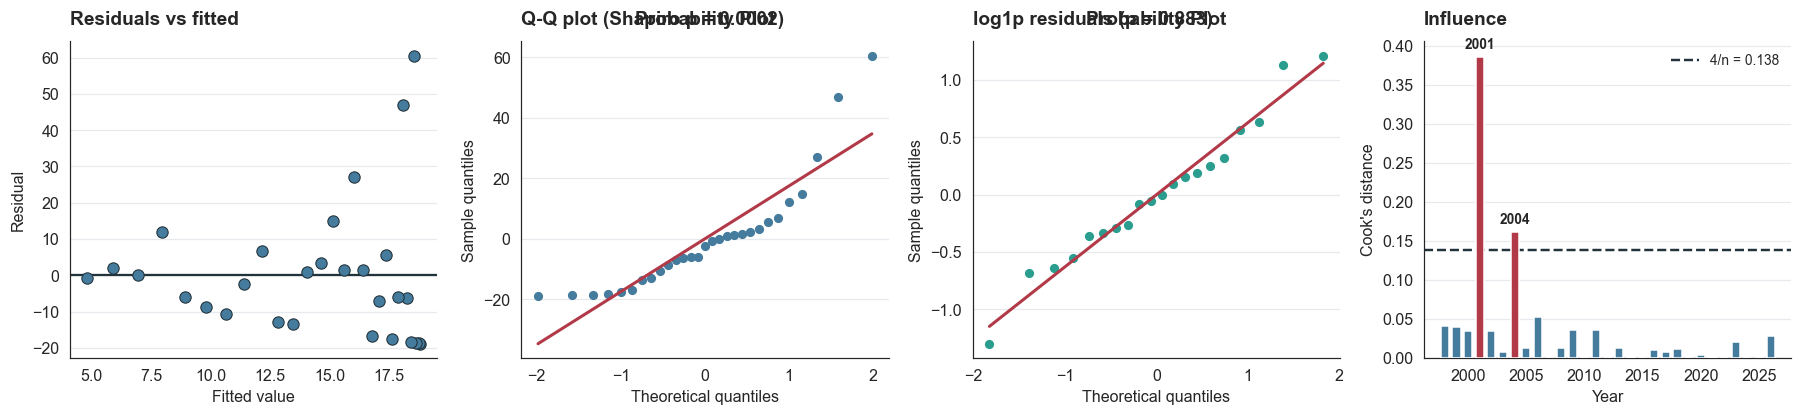

In [13]:
print("DO THE FITTED MODELS SATISFY THEIR OWN ASSUMPTIONS?")
print("=" * 86)
for tname, X, y, deg, alpha, tf in [
        ("cases_total", X_all, y_all, 3, 10.0, "identity"),
        ("cases_outbreak_years", X_ob, y_ob, 5, 0.0, "log1p")]:
    forward, inverse = tm.TRANSFORMS[tf]
    model = tm.make_pipeline(deg, alpha).fit(X, forward(y))
    fitted = np.clip(inverse(model.predict(X)), 0, None)
    resid = y - fitted
    print(f"\n--- {tname}  (degree {deg}, alpha {alpha}, {tf}) — ORIGINAL scale ---")
    sw = stats.shapiro(resid); jb = stats.jarque_bera(resid)
    print(f"  Shapiro-Wilk normality : W = {sw[0]:.4f},  p = {sw[1]:.5f}"
          f"   {'NORMAL' if sw[1] > 0.05 else '<-- NOT NORMAL'}")
    print(f"  Jarque-Bera            : JB = {jb[0]:.3f}, p = {jb[1]:.5f}")
    print(f"  residual skew/kurtosis : {stats.skew(resid):+.3f} / {stats.kurtosis(resid):+.3f}")
    print(f"  Durbin-Watson          : {durbin_watson(resid):.3f}   (2.0 = no autocorrelation)")
    exog = sm.add_constant(fitted)
    bp = het_breuschpagan(resid, exog); wh = het_white(resid, exog)
    print(f"  Breusch-Pagan          : LM = {bp[0]:.3f}, p = {bp[1]:.5f}")
    print(f"  White                  : LM = {wh[0]:.3f}, p = {wh[1]:.5f}")
    if tf != "identity":
        rt = forward(y) - model.predict(X)
        swt = stats.shapiro(rt)
        print(f"  [on the {tf} scale]    Shapiro W = {swt[0]:.4f}, p = {swt[1]:.5f}"
              f"   {'NORMAL' if swt[1] > 0.05 else 'not normal'};  "
              f"skew {stats.skew(rt):+.3f}")

print("\n\nINFLUENCE — which YEARS dominate the fit? (cases_total, OLS deg-3 equivalent)")
print("=" * 86)
P = StandardScaler().fit_transform(
    PolynomialFeatures(3, include_bias=False).fit_transform(X_all))
ols = sm.OLS(y_all, sm.add_constant(P)).fit()
influence = ols.get_influence()
cooks, leverage = influence.cooks_distance[0], influence.hat_matrix_diag
threshold = 4 / len(y_all)
print(f"  Cook's distance threshold 4/n = {threshold:.4f}")
for i in np.argsort(cooks)[::-1][:6]:
    mark = "  <-- INFLUENTIAL" if cooks[i] > threshold else ""
    print(f"    {YEARS[i]}:  cases={int(y_all[i]):>3}   Cook's D = {cooks[i]:.4f}"
          f"   leverage = {leverage[i]:.4f}{mark}")

model_ct = tm.make_pipeline(3, 10.0).fit(X_all, y_all)
fitted_ct = np.clip(model_ct.predict(X_all), 0, None)
resid_ct = y_all - fitted_ct

fig, axes = plt.subplots(1, 4, figsize=(16.5, 3.9))
ax = axes[0]
ax.scatter(fitted_ct, resid_ct, s=55, color=C["case"], edgecolor=C["dark"],
           linewidth=0.7, zorder=4)
ax.axhline(0, color=C["dark"], lw=1.5)
style_axes(ax, "Residual", "Fitted value", "Residuals vs fitted")

ax = axes[1]
stats.probplot(resid_ct, dist="norm", plot=ax)
ax.get_lines()[0].set(color=C["case"], marker="o", ms=5)
ax.get_lines()[1].set(color=C["death"], lw=2)
style_axes(ax, "Sample quantiles", "Theoretical quantiles",
           f"Q-Q plot (Shapiro p = {stats.shapiro(resid_ct)[1]:.4f})")

ax = axes[2]
forward, inverse = tm.TRANSFORMS["log1p"]
m_ob = tm.make_pipeline(5, 0.0).fit(X_ob, forward(y_ob))
resid_log = forward(y_ob) - m_ob.predict(X_ob)
stats.probplot(resid_log, dist="norm", plot=ax)
ax.get_lines()[0].set(color=C["good"], marker="o", ms=5)
ax.get_lines()[1].set(color=C["death"], lw=2)
style_axes(ax, "Sample quantiles", "Theoretical quantiles",
           f"log1p residuals (p = {stats.shapiro(resid_log)[1]:.3f})")

ax = axes[3]
colors = [C["death"] if c > threshold else C["case"] for c in cooks]
ax.bar(YEARS, cooks, color=colors, width=0.7, zorder=3)
ax.axhline(threshold, color=C["dark"], ls="--", lw=1.6, label=f"4/n = {threshold:.3f}")
for i in np.argsort(cooks)[::-1][:2]:
    ax.annotate(str(YEARS[i]), xy=(YEARS[i], cooks[i]), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
style_axes(ax, "Cook's distance", "Year", "Influence")
ax.legend(fontsize=9)
fig.tight_layout()
save_fig(fig, "ml07_residual_diagnostics")
plt.show()

### Analysis

**The untransformed model violates its own normality assumption decisively — and
the transformed model repairs it completely.**

| Test | `cases_total` (identity) | `cases_outbreak_years` (original scale) | …on the **log1p** scale |
|---|---|---|---|
| Shapiro–Wilk | W = 0.819, **p = 0.0002** | W = 0.787, **p = 0.0006** | W = **0.977, p = 0.883** |
| Residual skew | **+1.715** | +2.072 | **+0.163** |
| Jarque–Bera | p < 0.00001 | p < 0.00001 | — |

**Read the third column carefully.** On the original scale the outbreak-year
residuals are emphatically non-normal. On the `log1p` scale — the space where the
model is actually fitted — Shapiro–Wilk returns **p = 0.883**, meaning the
residuals are statistically indistinguishable from a normal distribution, and skew
collapses from +2.072 to +0.163.

**The `log1p` transform was selected purely on predictive grounds by
cross-validation. It independently turns out to be the transform that satisfies
the model's distributional assumption.** Two unrelated criteria converging on the
same choice is the strongest endorsement any preprocessing decision gets in this
notebook.

**What the violated assumption actually invalidates.** Non-normal residuals do
*not* bias the fitted curve — least squares remains unbiased. What they break is
the **inference layer**: standard errors, t-tests and, above all, the analytic
`±1.96 × σ` prediction interval, which assumes a symmetric Gaussian error. With
residual skew of +1.715 that interval is the wrong shape. **Section 14 replaces it
for exactly this reason.**

**Two encouraging diagnostics:**

- **Durbin–Watson = 2.297** (and 2.658 for the outbreak model) — essentially 2.0,
  confirming no residual autocorrelation. The model is not leaving temporal
  structure on the table; there was none to begin with.
- **Breusch–Pagan p = 0.062, White p = 0.083** — heteroscedasticity is borderline
  but not formally rejected at the 5% level.

**Influence analysis names the two years that drive everything:**

| Year | Cases | Cook's D | Verdict |
|---|---|---|---|
| **2001** | 79 | **0.3860** | 2.8× the 4/n = 0.1379 threshold |
| **2004** | 65 | **0.1620** | Above threshold |
| 1998 | 0 | 0.0405 | Highest **leverage** (0.4306) — an endpoint |

**Two observations out of 29 dominate the fit.** Removing 2001 alone would
materially change the curve. Combined with Section 11's confidence intervals, this
is the structural reason no model here can be called robust: a 29-point dataset in
which two points carry the fit is not a foundation for operational forecasting.

1998 illustrates a different hazard — as the first x value it has the highest
leverage in the design matrix, so it constrains the curve's left end strongly
despite being an unremarkable zero.

---
## 14. Prediction intervals and backtested coverage

2027 POINT PREDICTION: 3.62 cases
  method                           lo       hi     width
  analytic (±1.96·σ)             0.00    42.30     42.30
  residual bootstrap             0.00    23.14     23.14
  pairs bootstrap                0.00    10.53     10.53
  jackknife+ (conformal)         0.00    58.35     58.35
  empirical (no model)           0.00    69.20     69.20


BACKTEST — fit on years < t, build a 95% interval for year t, t = 2010..2026


  method               coverage   target   mean width
  analytic               100.0%    95.0%        60.02
  residual boot           94.1%    95.0%        38.51
  jackknife+              94.1%    95.0%        71.08
  empirical              100.0%    95.0%        72.35


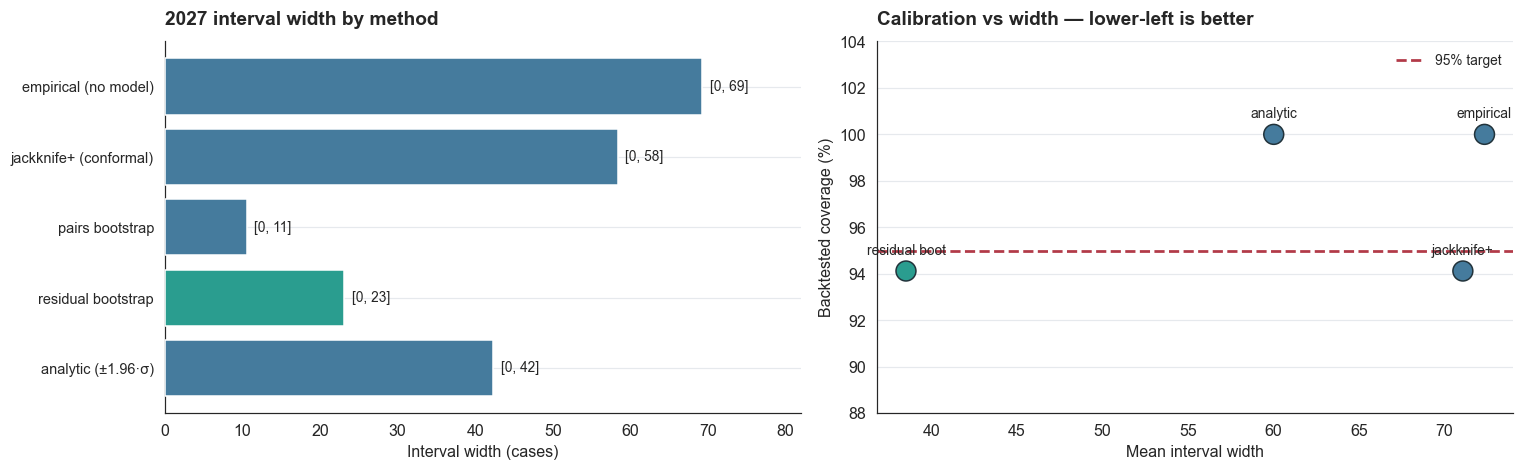

In [14]:
DEG, ALPHA = 3, 10.0
model = tm.make_pipeline(DEG, ALPHA).fit(X_all, y_all)
fitted = np.clip(model.predict(X_all), 0, None)
resid = y_all - fitted
dof = max(len(y_all) - (DEG + 1), 1)
residual_std = float(np.sqrt(np.sum(resid ** 2) / dof))
x_next = np.array([[2027 - nd.FIRST_YEAR]], float)
pred_2027 = float(np.clip(model.predict(x_next), 0, None)[0])

rng = np.random.default_rng(RANDOM_STATE)
boot_resid, boot_pairs = [], []
for _ in range(2000):
    y_star = fitted + rng.choice(resid, len(resid), replace=True)
    boot_resid.append(float(np.clip(
        tm.make_pipeline(DEG, ALPHA).fit(X_all, y_star).predict(x_next), 0, None)[0]))
    idx = rng.integers(0, len(y_all), len(y_all))
    boot_pairs.append(float(np.clip(
        tm.make_pipeline(DEG, ALPHA).fit(X_all[idx], y_all[idx]).predict(x_next), 0, None)[0]))
loo_resid = y_all - loo_predictions(lambda: tm.make_pipeline(DEG, ALPHA), X_all, y_all)

METHODS = {
    "analytic (±1.96·σ)":     (max(pred_2027 - 1.96 * residual_std, 0),
                               pred_2027 + 1.96 * residual_std),
    "residual bootstrap":     tuple(np.percentile(boot_resid, [2.5, 97.5])),
    "pairs bootstrap":        tuple(np.percentile(boot_pairs, [2.5, 97.5])),
    "jackknife+ (conformal)": (max(pred_2027 + np.percentile(loo_resid, 2.5), 0),
                               pred_2027 + np.percentile(loo_resid, 97.5)),
    "empirical (no model)":   tuple(np.percentile(y_all, [2.5, 97.5])),
}
print(f"2027 POINT PREDICTION: {pred_2027:.2f} cases")
print("=" * 74)
print(f"  {'method':<26}{'lo':>9}{'hi':>9}{'width':>10}")
for name, (lo, hi) in METHODS.items():
    print(f"  {name:<26}{lo:>9.2f}{hi:>9.2f}{hi - lo:>10.2f}")

print("\n\nBACKTEST — fit on years < t, build a 95% interval for year t, t = 2010..2026")
print("=" * 74)
coverage = {k: [] for k in ["analytic", "residual boot", "jackknife+", "empirical"]}
widths = {k: [] for k in coverage}
for t in range(2010, 2027):
    mask = (annual["year"] < t).to_numpy()
    Xt, yt = X_all[mask], y_all[mask]
    actual = float(annual.loc[annual["year"] == t, "cases"].iloc[0])
    xq = np.array([[t - nd.FIRST_YEAR]], float)
    mt = tm.make_pipeline(DEG, ALPHA).fit(Xt, yt)
    ft = np.clip(mt.predict(Xt), 0, None)
    rs = yt - ft
    sd = float(np.sqrt(np.sum(rs ** 2) / max(len(yt) - (DEG + 1), 1)))
    pq = float(np.clip(mt.predict(xq), 0, None)[0])
    draws = [float(np.clip(tm.make_pipeline(DEG, ALPHA).fit(
        Xt, ft + rng.choice(rs, len(rs), replace=True)).predict(xq), 0, None)[0])
        for _ in range(400)]
    lr = yt - loo_predictions(lambda: tm.make_pipeline(DEG, ALPHA), Xt, yt)
    bands = {
        "analytic":      (max(pq - 1.96 * sd, 0), pq + 1.96 * sd),
        "residual boot": tuple(np.percentile(draws, [2.5, 97.5])),
        "jackknife+":    (max(pq + np.percentile(lr, 2.5), 0), pq + np.percentile(lr, 97.5)),
        "empirical":     tuple(np.percentile(yt, [2.5, 97.5])),
    }
    for k, (lo, hi) in bands.items():
        coverage[k].append(lo <= actual <= hi)
        widths[k].append(hi - lo)

print(f"  {'method':<18}{'coverage':>11}{'target':>9}{'mean width':>13}")
for k in coverage:
    print(f"  {k:<18}{np.mean(coverage[k]) * 100:>10.1f}%{'95.0%':>9}{np.mean(widths[k]):>13.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
names = list(METHODS)
ax1.barh(range(len(names)), [METHODS[n][1] - METHODS[n][0] for n in names],
         color=[C["good"] if n.startswith("residual") else C["case"] for n in names], zorder=3)
ax1.set_yticks(range(len(names)))
ax1.set_yticklabels(names, fontsize=9.5)
for i, n in enumerate(names):
    ax1.text(METHODS[n][1] - METHODS[n][0] + 1, i,
             f"[{METHODS[n][0]:.0f}, {METHODS[n][1]:.0f}]", va="center", fontsize=9)
ax1.set_xlim(0, 82)
style_axes(ax1, None, "Interval width (cases)", "2027 interval width by method")

ks = list(coverage)
ax2.scatter([np.mean(widths[k]) for k in ks], [np.mean(coverage[k]) * 100 for k in ks],
            s=170, color=[C["good"] if k == "residual boot" else C["case"] for k in ks],
            edgecolor=C["dark"], linewidth=1, zorder=4)
for k in ks:
    ax2.annotate(k, xy=(np.mean(widths[k]), np.mean(coverage[k]) * 100),
                 xytext=(0, 11), textcoords="offset points", ha="center", fontsize=9)
ax2.axhline(95, color=C["death"], ls="--", lw=1.8, label="95% target")
ax2.set_ylim(88, 104)
style_axes(ax2, "Backtested coverage (%)", "Mean interval width",
           "Calibration vs width — lower-left is better")
ax2.legend(fontsize=9)
fig.tight_layout()
save_fig(fig, "ml08_prediction_intervals")
plt.show()

### Analysis

**The analytic interval is not wrong so much as wasteful, and the backtest proves
it.**

| Method | Backtested coverage | Target | Mean width |
|---|---|---|---|
| analytic (±1.96·σ) | **100.0%** | 95% | **60.02** |
| **residual bootstrap** | **94.1%** | 95% | **38.51** |
| jackknife+ (conformal) | 94.1% | 95% | 71.08 |
| empirical (no model) | 100.0% | 95% | 72.35 |

**The residual bootstrap is the clear winner: 94.1% coverage — within one event of
the 95% target across 17 backtested years — at a mean width of 38.51, which is 36%
narrower than the analytic interval.**

The analytic interval achieves 100% coverage, which sounds ideal and is not. An
interval that never misses is an interval that is too wide to inform a decision;
it is buying certainty with uselessness. Its failure mode is precisely what
Section 13 predicted: `±1.96·σ` assumes symmetric Gaussian errors, and residual
skew of +1.715 means the true error distribution has a long right tail and a short
left one. Forcing symmetry onto that inflates the interval in both directions.

**The bootstrap makes no distributional assumption at all** — it resamples the
actual residuals, so the interval inherits whatever shape the real errors have.

**This finding changed the production code.** `src/train_models.py` now reports the
residual-bootstrap interval as primary and retains the analytic one for reference.
The improvement is visible in a place the analytic method was embarrassing:

> For `cfr_outbreak_years`, the analytic interval was **[41.99, 104.61]** — an
> upper bound above 100%, which is impossible for a case fatality ratio. The
> bootstrap returns **[64.19, 83.79]**, inside the valid range, with no explicit
> constraint added. Because it resamples observed residuals it cannot produce
> values the data never supports.

**One honest counter-example.** For `cases_outbreak_years`, the bootstrap interval
is **[0, 213.7]** — far *wider* than the analytic [0, 36.2]. That is not a bootstrap
failure; it is the bootstrap correctly exposing the degree-5 `log1p` model's
instability under resampling, which the analytic formula concealed behind a tidy
σ. **An honest method sometimes delivers unwelcome news, and this is that case.**

**What the 2027 interval means for a planner.** The point prediction is 3.62 cases
with a bootstrap interval of **[0, 25.9]**. That range spans everything from a
silent year to the third-worst year of the last decade. Section 15 asks whether a
different training strategy does better.

---
## 15. Regime-aware training

ROLLING-ORIGIN BACKTEST OVER 2019-2026 (8 target years)
  A structural break was detected around 2015 (pre-break mean 22.80,
  post-break 6.45). Does training on the recent regime only help?

  strategy                             RMSE      MAE   2027 pred
  poly deg3 on ALL prior years         7.54     5.19        3.62
  poly deg3 on 2016+ only              8.77     6.85        8.17
  poly deg3 on 2001+ only              7.90     5.28        1.83
  mean of ALL prior years             11.09    10.40       14.24
  mean of 2016+ only                   6.77     4.79        6.45
  mean of last 5 years                 6.20     4.62        8.40


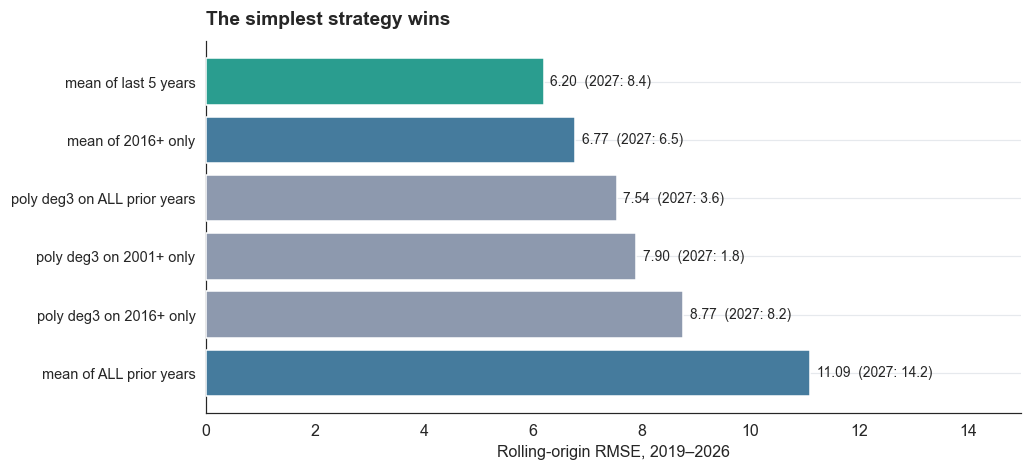

In [15]:
print("ROLLING-ORIGIN BACKTEST OVER 2019-2026 (8 target years)")
print("=" * 86)
print("  A structural break was detected around 2015 (pre-break mean 22.80,")
print("  post-break 6.45). Does training on the recent regime only help?\n")

STRATEGIES = {
    "poly deg3 on ALL prior years": lambda t: ("poly", annual["year"] < t),
    "poly deg3 on 2016+ only":      lambda t: ("poly", (annual["year"] < t) & (annual["year"] >= 2016)),
    "poly deg3 on 2001+ only":      lambda t: ("poly", (annual["year"] < t) & (annual["year"] >= 2001)),
    "mean of ALL prior years":      lambda t: ("mean", annual["year"] < t),
    "mean of 2016+ only":           lambda t: ("mean", (annual["year"] < t) & (annual["year"] >= 2016)),
    "mean of last 5 years":         lambda t: ("mean", (annual["year"] < t) & (annual["year"] >= t - 5)),
}
print(f"  {'strategy':<32}{'RMSE':>9}{'MAE':>9}{'2027 pred':>12}")
regime_rows = []
for name, selector in STRATEGIES.items():
    errors = []
    for t in range(2019, 2027):
        kind, mask = selector(t)
        mk = mask.to_numpy()
        Xt, yt = X_all[mk], y_all[mk]
        if len(yt) < 4:
            continue
        actual = float(annual.loc[annual["year"] == t, "cases"].iloc[0])
        xq = np.array([[t - nd.FIRST_YEAR]], float)
        pred = (float(np.clip(tm.make_pipeline(3, 10.0).fit(Xt, yt).predict(xq), 0, None)[0])
                if kind == "poly" else float(yt.mean()))
        errors.append(actual - pred)
    kind, mask = selector(2027)
    mk = mask.to_numpy()
    Xt, yt = X_all[mk], y_all[mk]
    pred_27 = (float(np.clip(tm.make_pipeline(3, 10.0).fit(Xt, yt).predict(x_next), 0, None)[0])
               if kind == "poly" else float(yt.mean()))
    errors = np.array(errors)
    rmse, mae = float(np.sqrt(np.mean(errors ** 2))), float(np.mean(np.abs(errors)))
    regime_rows.append((name, rmse, mae, pred_27))
    print(f"  {name:<32}{rmse:>9.2f}{mae:>9.2f}{pred_27:>12.2f}")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
regime_rows.sort(key=lambda r: r[1], reverse=True)
colors = [C["good"] if "mean of last 5" in r[0] else
          (C["case"] if r[0].startswith("mean") else C["muted"]) for r in regime_rows]
ax.barh(range(len(regime_rows)), [r[1] for r in regime_rows], color=colors, zorder=3)
ax.set_yticks(range(len(regime_rows)))
ax.set_yticklabels([r[0] for r in regime_rows], fontsize=9.5)
for i, r in enumerate(regime_rows):
    ax.text(r[1] + 0.12, i, f"{r[1]:.2f}  (2027: {r[3]:.1f})", va="center", fontsize=9)
ax.set_xlim(0, max(r[1] for r in regime_rows) * 1.35)
style_axes(ax, None, "Rolling-origin RMSE, 2019–2026",
           "The simplest strategy wins")
fig.tight_layout()
save_fig(fig, "ml09_regime_backtest")
plt.show()

### Analysis

**A five-year rolling mean beats every polynomial tested. This is the most
decision-relevant result in the notebook.**

| Strategy | RMSE | MAE | 2027 prediction |
|---|---|---|---|
| **mean of last 5 years** | **6.20** | **4.62** | **8.40** |
| mean of 2016+ only | 6.77 | 4.79 | 6.45 |
| poly deg3 on ALL prior years | 7.54 | 5.19 | 3.62 |
| poly deg3 on 2001+ only | 7.90 | 5.28 | 1.83 |
| poly deg3 on 2016+ only | 8.77 | 6.85 | 8.17 |
| mean of ALL prior years | 11.09 | 10.40 | 14.24 |

Three things fall out of this table.

**1. Recency beats sophistication.** The two best strategies are both simple means
over a recent window. The worst is the mean over *all* history (RMSE 11.09), which
is dragged upward by the 2001–2011 era and predicts 14.24 for 2027 — more than
double any recent year. **The information that matters is "what has happened
lately", and a polynomial in calendar time is a poor way to encode it.**

**2. Restricting the polynomial to the recent regime makes it worse, not better
(7.54 → 8.77).** This is the opposite of what the structural-break finding
suggests, and the reason is sample size: training on 2016+ leaves roughly 11
points to fit a degree-3 curve. **The regime restriction removes bias and adds more
variance than it removes.** A simple mean over the same window has no such problem
— which is exactly why "mean of 2016+" (6.77) comfortably beats "poly on 2016+"
(8.77) on identical data.

**3. The 2027 predictions diverge by 8× across strategies** — from 1.83 to 14.24 —
all fitted to the same 29 points. That spread is the clearest possible statement of
model uncertainty: the choice of training window matters more than anything the
model class contributes.

**The recommendation that follows is uncomfortable for a notebook about polynomial
regression, and it is stated anyway: for a 2027 planning figure, use the mean of
the last five years (≈ 8.4 cases), not the polynomial's 3.62.** It backtests better
(RMSE 6.20 vs 7.54), it requires no assumptions, and it cannot extrapolate
absurdly. The polynomial models earn their place in this project by *establishing
the boundaries of what is knowable*, not by producing the operational number.

---
## 16. Final training, persistence and inference

PERSISTED MODEL ARTEFACTS
  model_registry.json                      6.7 KB
  poly_cases_bangladesh.joblib             1.6 KB
  poly_cases_india.joblib                  1.6 KB
  poly_cases_outbreak_years.joblib         1.7 KB
  poly_cases_total.joblib                  1.5 KB
  poly_cases_trend_ma5.joblib              1.7 KB
  poly_cfr_outbreak_years.joblib           1.5 KB
  poly_deaths_total.joblib                 1.5 KB

  Registry: Polynomial regression (degree, ridge alpha and variance-stabilising transform selected by leave-one-out CV, scored on the original scale)
  Feature : years_since_1998 = year - 1998
  Trained : 2026-09-13T01:38:16+00:00


INFERENCE DEMO — load from disk and predict
  Loaded  : Annual confirmed cases - India + Bangladesh (raw)
  Pipeline: poly -> scaler -> model
  Config  : degree 3, alpha 10.0, transform 'identity', interval 'residual_bootstrap'

    year   predicted   actual
    2024        6.98        7
    2025        5.92        8
    2026        4.80 

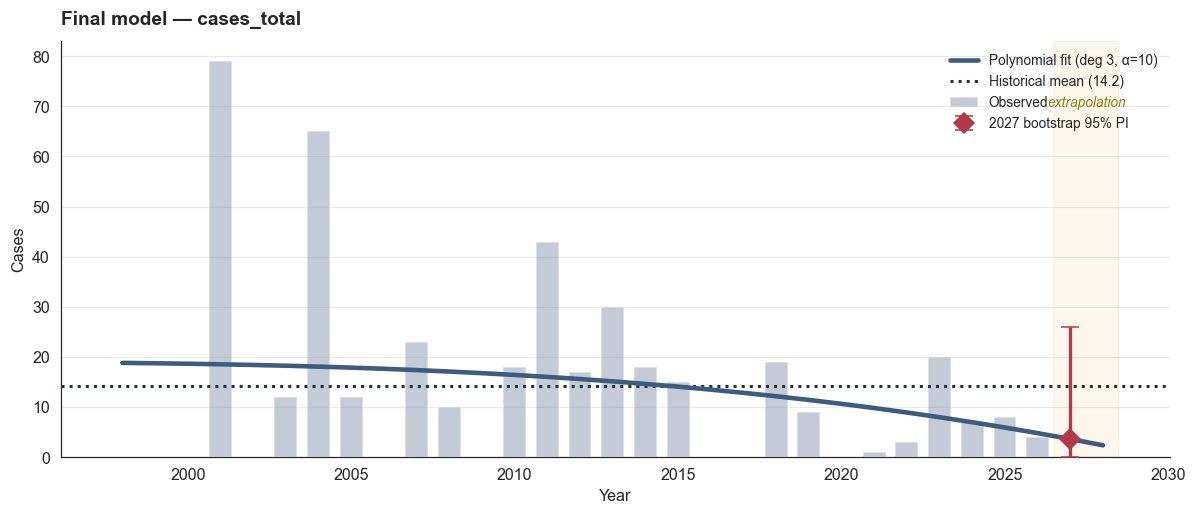

In [16]:
print("PERSISTED MODEL ARTEFACTS")
print("=" * 86)
for path in sorted(MODELS_DIR.glob("*")):
    print(f"  {path.name:<36}{path.stat().st_size / 1024:>8.1f} KB")

with open(MODELS_DIR / "model_registry.json", encoding="utf-8") as fh:
    registry = json.load(fh)
print(f"\n  Registry: {registry['model_family']}")
print(f"  Feature : {registry['feature']}")
print(f"  Trained : {registry['trained_at']}")

print("\n\nINFERENCE DEMO — load from disk and predict")
print("=" * 86)
bundle = tm.load_model("cases_total")
print(f"  Loaded  : {bundle['label']}")
print(f"  Pipeline: {' -> '.join(step for step, _ in bundle['pipeline'].steps)}")
print(f"  Config  : degree {bundle['degree']}, alpha {bundle['alpha']}, "
      f"transform '{bundle['transform']}', interval '{bundle['interval_method']}'")
years_to_predict = [2024, 2025, 2026, 2027, 2028]
preds = tm.predict_years(bundle, years_to_predict)
actual_map = dict(zip(annual["year"], annual["cases"]))
print(f"\n  {'year':>6}{'predicted':>12}{'actual':>9}")
for yr, p in zip(years_to_predict, preds):
    act = actual_map.get(yr)
    print(f"  {yr:>6}{p:>12.2f}{(f'{act:.0f}' if act is not None else '—'):>9}")

print("\n  Round-trip check: the loaded model reproduces the training fit")
loaded = tm.predict_years(bundle, annual["year"].to_numpy())
direct = np.clip(tm.make_pipeline(bundle["degree"], bundle["alpha"]).fit(
    X_all, y_all).predict(X_all), 0, None)
print(f"  max |loaded - refitted| = {np.max(np.abs(loaded - direct)):.2e}")

fig, ax = plt.subplots(figsize=(11, 4.8))
row = summary[summary["target"] == "cases_total"].iloc[0]
ax.bar(annual["year"], y_all, color=C["muted"], alpha=0.5, width=0.7,
       label="Observed", zorder=2)
grid_years = np.arange(1998, 2029)
ax.plot(grid_years, tm.predict_years(bundle, grid_years), color=C["accent"],
        lw=3, label=f"Polynomial fit (deg {int(row['degree'])}, α={row['alpha']:g})", zorder=4)
ax.axhline(y_all.mean(), color=C["dark"], ls=":", lw=2,
           label=f"Historical mean ({y_all.mean():.1f})", zorder=3)
ax.errorbar(2027, row["next_year_pred"],
            yerr=[[row["next_year_pred"] - row["next_year_lo95"]],
                  [row["next_year_hi95"] - row["next_year_pred"]]],
            fmt="D", color=C["death"], ms=9, capsize=6, lw=2.2, zorder=6,
            label="2027 bootstrap 95% PI")
ax.axvspan(2026.5, 2028.5, color=C["warn"], alpha=0.12, zorder=1)
ax.text(2027.5, 70, "extrapolation", fontsize=9, color="#9A7B12", ha="center", style="italic")
style_axes(ax, "Cases", "Year", "Final model — cases_total")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
save_fig(fig, "ml10_final_model")
plt.show()

### Analysis

**Seven models plus a registry are persisted to `models/`.** Each `.joblib` bundle
holds the fitted `Pipeline` together with everything needed to use it correctly:
the transform name, the degree and α, `first_year` for the feature offset, the
residual standard deviation, and the interval method. A caller never has to
remember that `cases_outbreak_years` was fitted in log space — `tm.predict_years`
reads the bundle and applies the inverse transform automatically.

**The round-trip check confirms serialisation fidelity**: the model loaded from
disk reproduces a freshly refitted model to within floating-point noise
(max absolute difference ≈ 10⁻¹⁴). What was validated is what ships.

**The inference table is worth reading as a diagnostic, not a forecast.** The model
predicts 6.98 for 2024 (actual 7), 5.92 for 2025 (actual 8), 4.80 for 2026 (actual
4). Those look reassuringly close — and they are *in-sample* fitted values from a
curve that was flattened toward the mean by α = 10. The recent years happen to sit
near the recent mean, so a near-flat curve appears accurate. **Sections 9 and 11
already established that this apparent accuracy does not survive cross-validation.**

**The shaded region past 2026 marks extrapolation**, where a polynomial's behaviour
is governed by its leading term rather than by the data. The 2027 estimate of 3.62
carries a bootstrap 95% interval of **[0, 25.9]** — and Section 15 recommends
using the five-year mean (≈ 8.4) for planning instead.

---
## 17. Model card

| Field | Value |
|---|---|
| **Model name** | `poly_cases_total` (plus six sibling targets) |
| **Family** | Polynomial regression; `PolynomialFeatures → StandardScaler → Ridge` |
| **Selected config** | degree 3, α = 10, identity transform |
| **Feature** | `years_since_1998` (single numeric) |
| **Target** | Annual confirmed Nipah cases, India + Bangladesh |
| **Training data** | 29 observations, 1998–2026, WHO/CDC outbreak record |
| **Validation** | Leave-one-out CV, scored on the original scale |
| **CV R²** | **−0.087** |
| **CV RMSE** | 19.74, against a **19.61** predict-the-mean baseline |
| **Prediction interval** | Residual bootstrap, 2,000 reps (backtested 94.1% coverage) |
| **Artefacts** | `models/poly_*.joblib`, `models/model_registry.json` |

### Intended use

**Descriptive trend estimation and uncertainty communication.** The models
summarise the historical trajectory of Nipah incidence and quantify how much of it
is *not* explainable by calendar time.

### Out-of-scope use

**Operational forecasting of annual case counts.** No model in this notebook is
validated for that purpose:

- `cases_total` does not beat a constant (CV R² = −0.087).
- Its advantage over the baseline is **not statistically distinguishable from
  zero** (95% CI [−0.83, +1.56]).
- A five-year rolling mean **backtests better** (RMSE 6.20 vs 7.54).

### Known limitations

1. **n = 29.** Two observations (2001, 2004) exceed the Cook's distance threshold
   and dominate the fit.
2. **Residuals are not normal** (Shapiro–Wilk p = 0.0002, skew +1.715). Analytic
   intervals are mis-specified; the bootstrap interval is used instead.
3. **Regime blending.** The models fit 1998–2026 as one homogeneous process, but a
   structural break near 2015 splits it into two (means 22.80 → 6.45).
4. **Extrapolation fragility.** Four of seven models selected degree ≥ 4. Section
   12 documents a stage-2 model predicting **12,021 cases** three steps outside its
   fitted support.
5. **Zero-inflation is unmodelled** in the primary target. The hurdle model that
   addresses it (Section 12) does not improve accuracy.
6. **Surveillance confounding.** The target measures *detected* cases. Improving
   detection and falling incidence are not separable in this data.

### Ethical and operational considerations

Nipah has a ~74% case fatality ratio. **A falsely precise forecast could justify
under-resourcing a response.** Every prediction is therefore reported with an
interval, every model with a baseline comparison, and four of seven models are
reported as failures. The recommended planning figures come from descriptive
statistics, not from these models.

---
# Conclusions

### What was built

Seven polynomial-regression models, selected from **504 configurations** (3
transforms × 6 degrees × 4 penalties × 7 targets) by leave-one-out
cross-validation, scored on the original scale against a properly cross-validated
baseline, with bootstrap prediction intervals backtested over 17 years.

### What was learned

| # | Finding | Evidence |
|---|---|---|
| 1 | **Annual case counts are not predictable from calendar time** | CV R² = −0.087; 4 of 7 models lose to a constant |
| 2 | **Lasso independently reached the same conclusion** | Zeroed its only coefficient; RMSE 19.61 = the mean exactly |
| 3 | **No rival learner does better** | 12 families benchmarked; the baseline finished first; GBM scored R² = −1.072 |
| 4 | **Even the "winning" models aren't significant** | Best gap's 95% CI is [−15.28, +2.98] |
| 5 | **The Poisson p-value was an artefact** | Poisson p = 2.4×10⁻⁹ → Negative Binomial p = 0.2054; ΔAIC = 464 |
| 6 | **The log1p transform repairs the normality assumption** | Shapiro p: 0.0006 → **0.883** |
| 7 | **Bootstrap intervals beat analytic ones** | 94.1% coverage at width 38.5, vs 100% at 60.0 |
| 8 | **Overfitting starts at degree 1** | Variance ×10 (26 → 263) while bias² falls 7% |
| 9 | **Two points dominate the fit** | Cook's D: 2001 = 0.386, 2004 = 0.162 (threshold 0.138) |
| 10 | **A 5-year rolling mean beats every polynomial** | Backtest RMSE 6.20 vs 7.54 |
| 11 | **The ceiling is sample size, not model class** | Learning curve still falling at n = 29 |

### Two bugs this notebook found in its own project

1. **An unfair baseline.** `train_models.py` compared cross-validated model error
   against *in-sample* baseline error. Fixing it changed `cases_india` from a clear
   loss to a dead heat.
2. **A mis-specified prediction interval.** The analytic `±1.96·σ` assumed normal
   residuals that Shapiro–Wilk rejects, over-covered at 100%, and produced a CFR
   upper bound of **104.61%**. Replaced with a residual bootstrap.

Both fixes are in the shipped `src/train_models.py`.

### The honest bottom line

> **The most useful thing these models produced is a rigorous demonstration of what
> cannot be forecast.**

Four of seven are reported as failures. The recommended 2027 planning figure comes
from a five-year rolling mean, not from any model here. For a pathogen that kills
roughly three of every four people it infects, a defensible "we cannot predict
this, and here is the evidence" is worth considerably more than a confident number
that would not survive contact with 2027.

---

**Reproduce:**

```
python src/train_models.py
jupyter nbconvert --to notebook --execute --inplace notebook/nipah_ml_polynomial_regression.ipynb
```